## Project scoping canvas

**Space Academy 2026 · Hyperspectral course · Week 2: project scoping and use case definition**

*This canvas follows `templates/project_scoping_template.md` and is the first section of the notebook. Sections are labelled C1 to C11 so they are not confused with the numbered notebook sections below. Numbers are the results of the executed notebook.*

### C1. Team

There is no team lead. Both members contribute equally (50 % each) and both reviewed and can explain the whole notebook.

| Name | Background | Role in the project |
|------|------------|---------------------|
| Mariolino Daniel III Julabar | Aerospace engineer | Data, preprocessing, uncertainty and product layers (equal contribution) |
| AlReem AlRowahi | Aerospace engineer | Method, validation and impact (equal contribution) |

### C2. Problem statement (≤ 80 words)

> Agricultural analysts near Massafra, Puglia, need to know where cropland is, but an NDVI threshold flags forest and grass too: only 16 % of pixels above NDVI 0.5 are cropland. Using one Tanager scene (30 April 2025), we test whether the full spectrum separates cropland, woody vegetation, grassland, built-up land and water better than narrow-band indices and simulated Sentinel-2 bands, on spatially independent reference pixels. Output: a land-cover map with confidence layers and a ranked inspection list.

### C3. Users and decisions

| Question | Your answer |
|----------|-------------|
| Who is the end user (organisation, role)? | A regional agri-environment analyst (for example in an agency that plans land-use or subsidy inspections). A defined persona; **no operational user has been consulted yet**. |
| Which decision will your output support? | Which land to send inspection teams to first. |
| What do they use today, and why is it not good enough? | Greenness indices such as NDVI > 0.5. They flag 131 km² as vegetation, of which only 16 % is cropland, and still miss 53 % of the cropland. |
| How often do they need the information? | Monthly in the growing season (the workflow reruns per scene; no operational schedule exists yet). |
| In what form do they need it? | Georeferenced maps (COGs), a ranked CSV of ~1 km cells with a low-confidence flag, an HTML report. A prototype, not a deployed service. |

### C4. Why hyperspectral?

NDVI uses two broad bands and works on any multispectral sensor; a threshold tuned on training pixels (NDVI > 0.25) already separates vegetation from non-vegetation well (accuracy 0.97), so for that question multispectral data would work equally well. The added value is **separating cropland from forest and grass in April**, which needs finer spectral detail: the **red edge** (about 700-740 nm; NDRE at 790/720 nm, red-edge position from 670/700/740/780 nm), the **shortwave-infrared water feature** (NDMI at 860/1,650 nm) and the **2,000-2,450 nm region**. We test this directly on the same pixels, labels and split: four indices versus ten simulated Sentinel-2 bands versus the full 352-band spectrum. Result: full spectrum beats Sentinel-2-like bands by +0.052 macro-F1 (95 % CI 0.039 to 0.071).

### C5. Area of interest and time frame

- AOI (name, bounding box in lon/lat, size in km²): central 512 × 512 pixels of the scene near Massafra, Taranto, Apulia, Italy; W 17.0598, S 40.5076, E 17.2456, N 40.6425; 236 km² (EPSG:32633, 30 m pixels).
- Period of interest: 30 April 2025, 10:17:24 UTC (single date).
- Why this AOI is representative of the wider problem: a mix of coast, towns, farmland, forest and grassland, as in much of southern Italy. It is not representative of all Apulia.

### C6. Data availability

| Dataset | Scene IDs / product | Date(s) | Cloud % | Role in the project |
|---------|---------------------|---------|---------|---------------------|
| Tanager | `20250430_101724_87_4001`, ortho surface-reflectance HDF5 | 30 Apr 2025 | 2 % in the catalogue; 2.0 % cloud and 0.4 % cirrus flagged in the crop (beta masks, false positives over bright surfaces) | primary analysis |
| EnMAP / Sentinel-2 / Landsat (optional) | not used: every Sentinel-2 scene within ±8 days has 18-90 % cloud over the crop | n/a | n/a | replaced by simulated Sentinel-2-like bands |
| Reference / labels | ESA WorldCover 2021 v200, pure 30 m pixels, five classes | 2021 | n/a | training / validation (a proxy, not field truth) |
| Ancillary | none | n/a | n/a | n/a |

- [x] At least one usable Tanager scene covers the AOI (checked with thumbnails and QA masks; 98.0 % valid pixels).
- [x] Change detection is not needed (single date).
- [x] A source of reference data for validation exists (WorldCover; limits stated in section 8.3).

### C7. Method (first version)

1. Preprocessing (bad bands, masks, subsetting): remove provider-flagged bands and 0-400, 1,340-1,445, 1,790-1,970 and 2,450+ nm (352 of 426 bands kept); mask no-data, cloud and cirrus; central crop.
2. Features: NDVI, NDRE, NDMI, red-edge position; ten simulated Sentinel-2 bands; full spectrum.
3. Core analysis (classification): NDVI-threshold baseline, then the best of four classifiers per feature set chosen on validation blocks, scored once on test blocks.
4. Output product: land-cover, confidence, NDVI, NDVI σ and baseline COGs, ranked inspection cells, HTML report.

`Tanager scene → QA and band removal → 3 feature sets (4 indices | 10 Sentinel-2-like | 352 full) → spatial block split → model per set (chosen on validation) → test once with 95 % CI → maps, COGs, report`

### C8. Validation plan

| Item | Plan |
|------|------|
| Reference data | WorldCover 2021, pure 3 × 3 cells per pixel, five classes (cropland, woody vegetation, grassland, built-up/bare, water). |
| Metric(s) | OA, macro-F1, per-class precision, recall, F1, IoU, confusion matrices, 95 % block-bootstrap confidence intervals. |
| Sampling / split | Whole 40 × 40-pixel blocks to train / validation / test (50 / 20 / 30 %). |
| Success criterion | macro-F1 ≥ 0.80 on test blocks, and the CI of the full-spectrum minus Sentinel-2-like difference excludes 0. Result: macro-F1 0.823 (CI 0.793-0.840), met on the point estimate and marginal on the CI; difference +0.052 (CI 0.039-0.071), met. |

### C9. Deliverables

- [x] Reproducible notebook (runs top to bottom)
- [x] Output layer(s) as Cloud-Optimised GeoTIFF + metadata
- [x] Validation table
- [x] Mock-up or prototype of how the user receives the result (HTML report, ranked inspection cells)
- [x] Final presentation (`presentation.pdf`)

### C10. Risks and fallbacks

| Risk | Likelihood | Impact | Fallback |
|------|-----------|--------|----------|
| No cloud-free scene over the AOI | Low (2 % flagged, mostly false positives) | Low | Cloud and cirrus pixels are masked; flags inspected visually |
| No reference data | Medium | High | WorldCover 2021 as a proxy; 2025 field or parcel labels as the improvement |
| Method does not separate the classes | Occurred for cropland vs grassland | Medium | Report the confusion; second date would help |
| Reference differs from reality in 2025 | High | Medium | State results as agreement with the reference |

### C11. Timeline

| When | Milestone |
|------|-----------|
| Thu 19 Nov | Canvas drafted in the scoping session |
| Mon 23 Nov | Canvas due · data downloaded, first quicklooks (done) |
| Tue 24 Nov | Working method on one scene (done) |
| Wed 25 Nov | Build afternoon: final validation numbers (done) |
| Thu 26 Nov | Submission in the morning, presentation in the afternoon |

*Data: Tanager STAC Data © 2025 Planet Labs PBC (CC-BY-4.0); ESA WorldCover 2021 v200 (CC-BY 4.0).*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mariolinoiii/team_demeter_hyperspectral_project/blob/main/project.ipynb)

*Running in Colab? Run the setup cell below first. It checks the packages this notebook needs and that `src/demeter.py` is present. Running locally? It does nothing.*

# 🛰️ Project Demeter: Can hyperspectral data separate cropland from other vegetation near Massafra (Apulia, Italy)?
### Space Academy 2026 · Hyperspectral course · Final graduation project

**Team:** Mariolino Daniel III Julabar, AlReem AlRowahi · **Theme:** Agriculture · **Version:** 15 November 2026

**How to run:** *Restart & Run All*. The notebook downloads the Tanager scene (about 1.1 GB) and one ESA WorldCover tile the first time and caches them in `data/` (or in the folder named by the environment variable `DEMETER_DATA_DIR`). The raw scene is **not** part of the submission; the scene ID is in the config cell. Typical run time is 6-13 minutes on a laptop.

**In one paragraph.** NDVI is the quick answer to "where is the vegetation?", but around Massafra most green pixels are forest, scrub and grass, not crops. A person planning field inspections of agricultural land needs *cropland*, which NDVI alone cannot give. We test, on spatially independent reference pixels, how well (a) an NDVI threshold finds vegetation and (b) the full 352-band spectrum separates five land-cover classes, compared with four narrow-band indices and with a simulated Sentinel-2-like sensor made from the same scene.

In [4]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this installs the geospatial packages Colab does not ship and checks that the team folder
# (with src/demeter.py) was uploaded next to the notebook. Locally it does nothing: your environment is already active.
import pathlib
import platform
import subprocess
import sys
import shutil

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "h5py", "rasterio", "pyproj", "requests", "scikit-learn"], check=True)

    # If demeter.py is at the root, move it to src/ so the internal imports work
    root_file = pathlib.Path("demeter.py")
    src_dir = pathlib.Path("src")
    if root_file.exists():
        src_dir.mkdir(exist_ok=True)
        shutil.move(str(root_file), str(src_dir / "demeter.py"))

    if not pathlib.Path("src/demeter.py").exists():
        raise FileNotFoundError("Upload the whole team folder (it contains src/demeter.py) to Colab, then run this cell again.")
    print("Colab ready")
else:
    print("Local environment: Python", platform.python_version())

Colab ready


## 1. Problem, user and decision
*(Key points from the scoping canvas above.)*

- **Problem:** in southern Italy "green" is not the same as "agricultural". An NDVI threshold flags forest, maquis and grassland together with crops, so a map of "vegetation" overstates the land an agricultural analyst needs to look at.
- **User and decision supported:** a regional agri-environment analyst (for example in an agency that plans land-use or subsidy inspections, or irrigation visits) deciding *which land to send inspection teams to first*. **No operational user has been consulted yet**; the user is a defined persona, and a pilot conversation is listed as a next step.
- **Why hyperspectral:** the red edge (about 700-740 nm; NDRE 790/720 nm, red-edge position 670/700/740/780 nm), the shortwave-infrared water feature (NDMI 860/1,650 nm) and the 2,000-2,450 nm region. A tuned NDVI already separates vegetation from non-vegetation, so the added value is separating **cropland** from forest and grass.
- **Success criterion:**
  * *Accuracy target:* macro-F1 ≥ 0.80 on independent, spatially separated test pixels. This number comes from our first scoping canvas, written before any validation existed.
  * *Added-value target:* the 95 % confidence interval of the macro-F1 difference between the full spectrum and the Sentinel-2-like bands excludes zero. We set this one when we designed the comparison, after an exploratory first run (see the development note in section 7).

  We report below whether each target was met. We did not change either target after the final results.
- **Questions we answer.** (1) *Baseline:* how well does an NDVI threshold separate vegetation from non-vegetation? (2) *What hyperspectral adds:* can the full spectrum separate cropland, woody vegetation, grassland, built-up/bare land and water better than (a) four narrow-band indices and (b) the ten broad bands a Sentinel-2-like multispectral sensor would record?
- **Out of scope.** One date, one scene. No crop type, crop health, disease or yield diagnosis, and no change detection.

## 2. Configuration

Everything a reader may want to change is in this one cell: the scene, the crop, the excluded wavelength ranges, the thresholds, the split design and the random seed. Fixed spectral definitions (which wavelength each index uses) sit next to the code that uses them so that the wavelengths are visible.

In [5]:
import os, sys, json, time, hashlib, platform, warnings, base64, io, importlib.metadata
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import h5py, rasterio
from scipy import ndimage as ndi
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("src").resolve()))        # helper module in src/
import demeter as dm

T_START = time.time()
ROOT = Path.cwd()
DATA = Path(os.environ.get("DEMETER_DATA_DIR", ROOT / "data"))     # big downloads live here
DATA.mkdir(parents=True, exist_ok=True)
OUT, FIG, VAL = ROOT / "outputs", ROOT / "outputs" / "figures", ROOT / "validation"
for d in (OUT, FIG, VAL):
    d.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    project="Project_Demeter",
    scene_id="20250430_101724_87_4001",
    h5_url="https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/ortho_sr_hdf5/20250430_101724_87_4001_ortho_sr_hdf5.h5",
    window=None,                                     # (row0, row1, col0, col1) in scene pixels; None = central crop_size x crop_size window
    crop_size=512,                                   # central 512 x 512 pixels = 15.36 km square at 30 m
    use_cloud_mask=True,                             # drop pixels flagged cloud/cirrus (inspected in sections 3 and 4)
    accuracy_target_macro_f1=0.80,                   # success criterion from the scoping canvas
    bad_ranges_nm=[(0, 400), (1340, 1445), (1790, 1970), (2450, 3000)],   # noisy edges + water-vapour absorption
    ndvi_baseline_threshold=0.5,                     # the threshold proposed in our first canvas
    sensitivity_thresholds=[0.2, 0.3, 0.4, 0.5, 0.6],
    block_size=40,                                   # pixels; whole blocks go to train, validation or test
    split_fractions=(0.5, 0.2, 0.3),
    train_per_class=3000,                            # training pixels drawn per class (training blocks only)
    n_boot=1000,                                     # block-bootstrap replicates
    seed=42,
)
SEED = CONFIG["seed"]
TARGET = CONFIG["accuracy_target_macro_f1"]

CLASS_COLOURS = ["#E69F00", "#117733", "#A6D96A", "#7F7F7F", "#0072B2"]   # cropland, woody, grass, built/bare, water
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()
print("Config loaded. Data folder:", DATA.name)

Config loaded. Data folder: data


## 3. Data and quality control

### 3.1 The Tanager scene

Tanager is a hyperspectral satellite: for every 30 m pixel it records a continuous spectrum in about 5 nm steps from 376 to 2,499 nm. The file is an HDF5 product with orthorectified **surface reflectance** (already atmospherically corrected), a per-pixel, per-band **uncertainty** layer, and binary cloud, cirrus and no-data masks. We read the map grid (projection, corner, pixel size) from the file's own metadata, so the course helper script is not needed.

,value
Scene ID,20250430_101724_87_4001
Acquisition,2025-04-30 10:17:24 UTC (from the scene ID)
Map projection,EPSG:32633 (UTM zone 33N)
Pixel size,30 m
Spectral,"426 bands, 376-2499 nm, FWHM about 6.1 nm"
Scene size,766 rows x 876 cols
Analysis crop (central),"rows 127-639, cols 182-694"
Crop area,235.9 km2
Crop bounding box (lon/lat),"W 17.0598, S 40.5076, E 17.2456, N 40.6425"


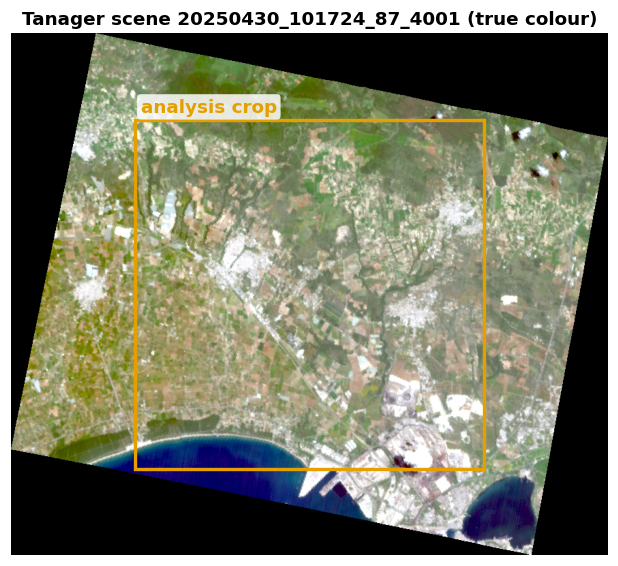

In [6]:
_t = time.time()
SCENE = dm.download(CONFIG["h5_url"], DATA / "scene.h5")
T_DOWNLOAD = time.time() - _t
h5 = h5py.File(SCENE, "r")
grid = dm.scene_grid(h5)
window = dm.crop_window(grid, CONFIG["crop_size"]) if CONFIG["window"] is None else tuple(CONFIG["window"])   # (row0, row1, col0, col1)
transform = dm.affine_for(grid, window)
wl_all, good_all, fwhm_all = dm.band_metadata(h5)
H, W = window[1] - window[0], window[3] - window[2]

from pyproj import Transformer
to_lonlat = Transformer.from_crs(grid["epsg"], 4326, always_xy=True)
xs = [transform.c, transform.c + W * grid["pixel"]]
ys = [transform.f - H * grid["pixel"], transform.f]
west, south = to_lonlat.transform(xs[0], ys[0]); east, north = to_lonlat.transform(xs[1], ys[1])
crop_area_km2 = H * W * (grid["pixel"] / 1000) ** 2

info = pd.DataFrame({"value": [
    CONFIG["scene_id"], "2025-04-30 10:17:24 UTC (from the scene ID)", f"EPSG:{grid['epsg']} (UTM zone 33N)",
    f"{grid['pixel']:.0f} m", f"{len(wl_all)} bands, {wl_all.min():.0f}-{wl_all.max():.0f} nm, FWHM about {fwhm_all.mean():.1f} nm",
    f"{grid['ydim']} rows x {grid['xdim']} cols", f"rows {window[0]}-{window[1]}, cols {window[2]}-{window[3]}",
    f"{crop_area_km2:.1f} km2", f"W {west:.4f}, S {south:.4f}, E {east:.4f}, N {north:.4f}"]},
    index=["Scene ID", "Acquisition", "Map projection", "Pixel size", "Spectral", "Scene size", "Analysis crop (central)",
           "Crop area", "Crop bounding box (lon/lat)"])
display(info)

# Whole-scene true-colour thumbnail with the analysis crop outlined
def stretch(a, lo=2, hi=98):
    ok = np.isfinite(a)
    p = np.percentile(a[ok], [lo, hi])
    return np.clip((a - p[0]) / (p[1] - p[0]), 0, 1)

bands_rgb = [dm.nearest(wl_all, w) for w in (665, 560, 480)]
planes = []
for b in bands_rgb:
    a = h5[dm.REFLECTANCE][b, :, :].astype("float32"); a[a <= -9000] = np.nan
    planes.append(stretch(a))
rgb_full = np.nan_to_num(np.dstack(planes), nan=0) ** (1 / 2.2)
fig, ax = plt.subplots(figsize=(7, 6.2))
ax.imshow(rgb_full)
ax.add_patch(Rectangle((window[2], window[0]), W, H, fill=False, ec="#E69F00", lw=2.2))
ax.text(window[2] + 8, window[0] - 12, "analysis crop", color="#E69F00", fontsize=12, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_title("Tanager scene 20250430_101724_87_4001 (true colour)"); ax.axis("off")
save(fig, "f01_scene_overview")

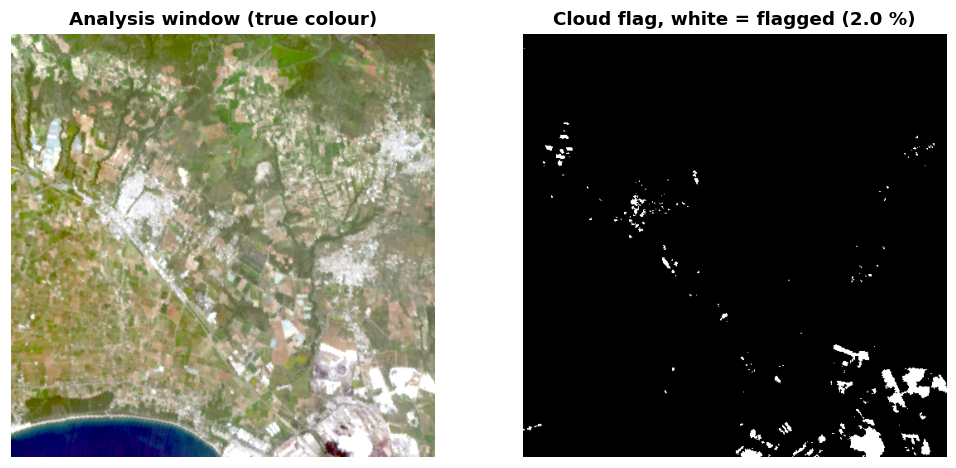

usable pixels in window (no-data, cloud and cirrus all clear): 98.0 %


In [7]:
# Template check: look at the analysis window and the QA masks before any analysis
nodata = dm.read_flag(h5, "nodata_pixels", window)
cloud = dm.read_flag(h5, "beta_cloud_mask", window)
cirrus = dm.read_flag(h5, "beta_cirrus_mask", window)
r0, r1, c0, c1 = window
planes_w = []
for b_ in bands_rgb:
    a_ = h5[dm.REFLECTANCE][b_, r0:r1, c0:c1].astype("float32"); a_[a_ <= -9000] = np.nan
    planes_w.append(stretch(a_))
rgb_window = np.nan_to_num(np.dstack(planes_w), nan=0) ** (1 / 2.2)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(rgb_window); ax[0].set_title("Analysis window (true colour)")
ax[1].imshow(cloud, cmap="gray"); ax[1].set_title(f"Cloud flag, white = flagged ({cloud.mean() * 100:.1f} %)")
for a_ in ax: a_.axis("off")
save(fig, "f01b_window_and_cloud_flag")
print(f"usable pixels in window (no-data, cloud and cirrus all clear): {(~(nodata | cloud | cirrus)).mean() * 100:.1f} %")

### 3.2 Independent reference labels: ESA WorldCover 2021

To measure accuracy we need reference labels that were **not** made from our own data. We use **ESA WorldCover 2021 v200** (10 m land-cover map made from Sentinel-1 and Sentinel-2; licence CC-BY 4.0; global overall accuracy 76.7 %, ESA validation report). It is independent of Tanager and of NDVI.

It is a *proxy* for ground truth, not ground truth, so we protect the evaluation in three ways:

1. **Pure pixels only.** One Tanager pixel (30 m) covers 3 x 3 WorldCover cells. We keep a pixel as a label only if **all nine cells agree**, which removes mixed edge pixels.
2. **Five classes.** Cropland · Woody vegetation (tree cover + shrubland) · Grassland · Built-up / bare · Water. Wetland (0.1 %) is dropped.
3. **Honest limits.** The map is from **2021** and Tanager is **April 2025**, so crop fields can have changed; WorldCover's own errors are inside our labels. Accuracy measured here is therefore *agreement with WorldCover*, and the true accuracy against the ground could be higher or lower.

,WorldCover class,share of crop (%),our class
0,Tree cover,33.4,Woody vegetation
1,Shrubland,6.8,Woody vegetation
2,Grassland,23.3,Grassland
3,Cropland,21.3,Cropland
4,Built-up,9.9,Built-up / bare
5,Bare / sparse,1.4,Built-up / bare
6,Water,3.9,Water
7,Wetland,0.1,(dropped)


Pure reference pixels: 168,547 of 262,144 (64.3 %)


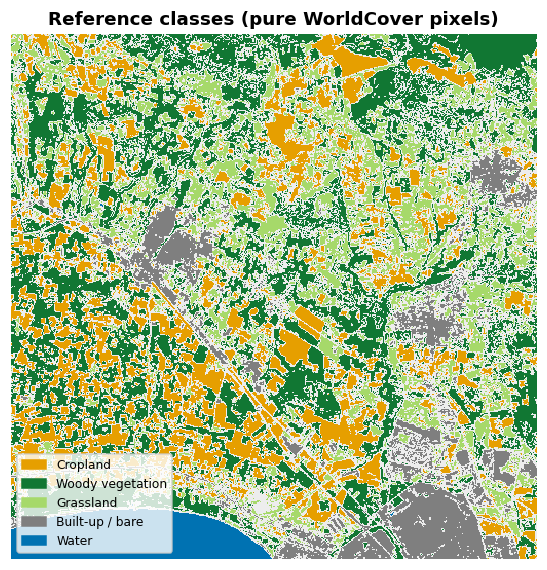

In [8]:
WC_NAMES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up", 60: "Bare / sparse",
            70: "Snow / ice", 80: "Water", 90: "Wetland", 95: "Mangroves", 100: "Moss / lichen"}
modal, pure = dm.worldcover_on_grid(transform, (H, W), grid["epsg"], cache=DATA / "worldcover_cache.npz")

comp = pd.DataFrame({
    "WorldCover class": [WC_NAMES[c] for c in dm.WC_CODES if (modal == c).any()],
    "share of crop (%)": [100 * (modal == c).mean() for c in dm.WC_CODES if (modal == c).any()]})
comp["our class"] = [dm.CLASS_NAMES[dm.WC_TO_CLASS[c]] if c in dm.WC_TO_CLASS else "(dropped)" for c in dm.WC_CODES if (modal == c).any()]
display(comp.round(1))
print(f"Pure reference pixels: {(pure >= 0).sum():,} of {H*W:,} ({100*(pure >= 0).mean():.1f} %)")

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(6.5, 6.2))
show = np.ma.masked_less(pure, 0)
ax.imshow(np.full((H, W, 3), 0.93))                      # light-grey background = unlabelled pixels
ax.imshow(show, cmap=ListedColormap(CLASS_COLOURS), vmin=-0.5, vmax=4.5, interpolation="nearest")
ax.set_title("Reference classes (pure WorldCover pixels)"); ax.axis("off")
handles = [Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLOURS]
ax.legend(handles, dm.CLASS_NAMES, loc="lower left", fontsize=8, frameon=True)
save(fig, "f02_reference_labels")

## 4. Preprocessing

Steps, and why each one is needed:

1. **Bad-band removal.** We drop bands the provider flags as poor *and* three ranges of our own: below 400 nm and above 2,450 nm (noisy sensor edges) and the two atmospheric water-vapour absorption windows, 1,340-1,445 nm and 1,790-1,970 nm (almost no signal reaches the sensor there).
2. **Crop.** The central 512 x 512 pixels (235.9 km²) keep memory small and the area diverse (coast to countryside).
3. **Pixel masks.** A pixel is *valid* only if the no-data, cloud and cirrus masks are clear and all retained bands are finite. The cloud and cirrus masks are labelled *beta* by the provider, so we inspect them below rather than trust them blindly.

,pixels,% of crop
crop pixels,262144,100.00
no-data flagged,0,0.00
cloud flagged,5203,1.98
cirrus flagged,983,0.37
non-finite spectra,0,0.00
VALID pixels,256933,98.01


,count
bands in file,426
flagged bad by provider,58
bands retained for analysis,352


Negative reflectance in at least one retained band: 3.3 % of pixels (expected over dark water/shadow; kept, not clipped).


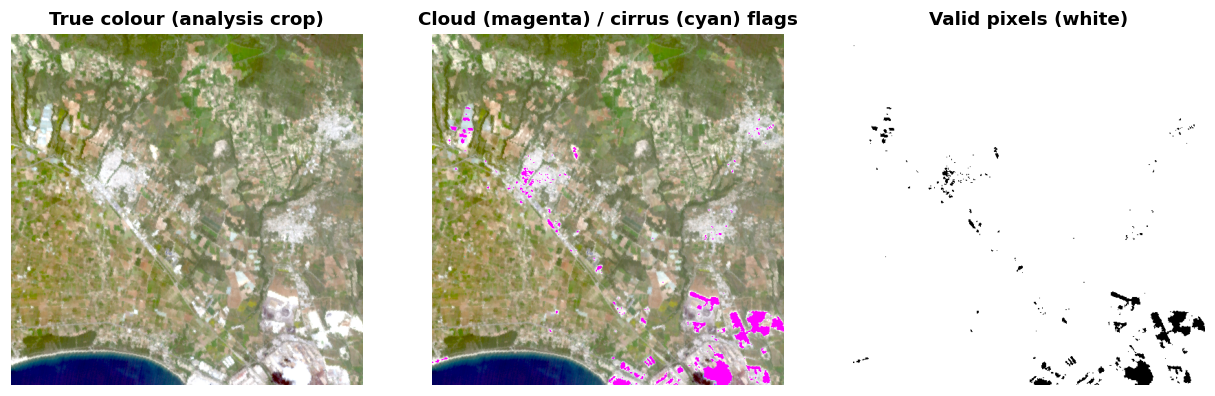

**Visual QA result.** In the true-colour image the flagged pixels sit on large bright industrial and urban surfaces and greenhouse roofs, not on cloud shapes; 88% of the flagged pixels are WorldCover built-up or bare land. The beta cloud mask therefore appears to give **false positives over very bright surfaces**. We still treat flagged pixels as invalid (the conservative choice, and we have no cloud-free comparison image). The price is that 20% of the pure built-up/bare reference pixels are removed, so the built-up class is under-sampled for its brightest surfaces and its accuracy is probably optimistic.

In [9]:
keep = dm.retained_bands(wl_all, good_all, CONFIG["bad_ranges_nm"])
wl = wl_all[keep]                                                  # retained wavelengths
cube = dm.read_cube(h5, window)                                    # (426, 512, 512)
core = cube[keep]                                                  # retained bands only
del cube
nodata = dm.read_flag(h5, "nodata_pixels", window)
cloud = dm.read_flag(h5, "beta_cloud_mask", window)
cirrus = dm.read_flag(h5, "beta_cirrus_mask", window)
finite = np.isfinite(core).all(axis=0)
mask_ok = (~cloud & ~cirrus) if CONFIG["use_cloud_mask"] else np.ones_like(cloud, dtype=bool)
valid = finite & ~nodata & mask_ok

qa = pd.DataFrame({"pixels": [H * W, int(nodata.sum()), int(cloud.sum()), int(cirrus.sum()), int((~finite).sum()), int(valid.sum())]},
                  index=["crop pixels", "no-data flagged", "cloud flagged", "cirrus flagged", "non-finite spectra", "VALID pixels"])
qa["% of crop"] = (100 * qa["pixels"] / (H * W)).round(2)
display(qa)
bands_tbl = pd.DataFrame({"count": [len(wl_all), int((~good_all).sum()), int(keep.sum())]},
                         index=["bands in file", "flagged bad by provider", "bands retained for analysis"])
display(bands_tbl)
print(f"Negative reflectance in at least one retained band: {100*(core < 0).any(axis=0).mean():.1f} % of pixels (expected over dark water/shadow; kept, not clipped).")

# Visual QA: where are the flagged pixels, and are they really cloud?
rgb_idx = [dm.nearest(wl, w) for w in (665, 560, 480)]
rgb = np.nan_to_num(np.dstack([stretch(core[i]) for i in rgb_idx]), nan=0) ** (1 / 2.2)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
axes[0].imshow(rgb); axes[0].set_title("True colour (analysis crop)")
ov = rgb.copy(); ov[cloud] = [1, 0, 1]; ov[cirrus & ~cloud] = [0, 1, 1]
axes[1].imshow(ov); axes[1].set_title("Cloud (magenta) / cirrus (cyan) flags")
axes[2].imshow(valid, cmap="gray"); axes[2].set_title("Valid pixels (white)")
for a in axes: a.axis("off")
save(fig, "f03_qa_masks")

flag = cloud | cirrus
share_bright = float(np.isin(modal[flag], [50, 60]).mean())
lost_builtup = float(((pure == 3) & flag).sum() / max((pure == 3).sum(), 1))
display(Markdown(
    f"**Visual QA result.** In the true-colour image the flagged pixels sit on large bright industrial and urban surfaces and greenhouse roofs, not on cloud shapes; "
    f"{share_bright:.0%} of the flagged pixels are WorldCover built-up or bare land. The beta cloud mask therefore appears to give **false positives over very bright surfaces**. "
    f"We still treat flagged pixels as invalid (the conservative choice, and we have no cloud-free comparison image). The price is that {lost_builtup:.0%} of the pure built-up/bare reference pixels are removed, "
    f"so the built-up class is under-sampled for its brightest surfaces and its accuracy is probably optimistic."))

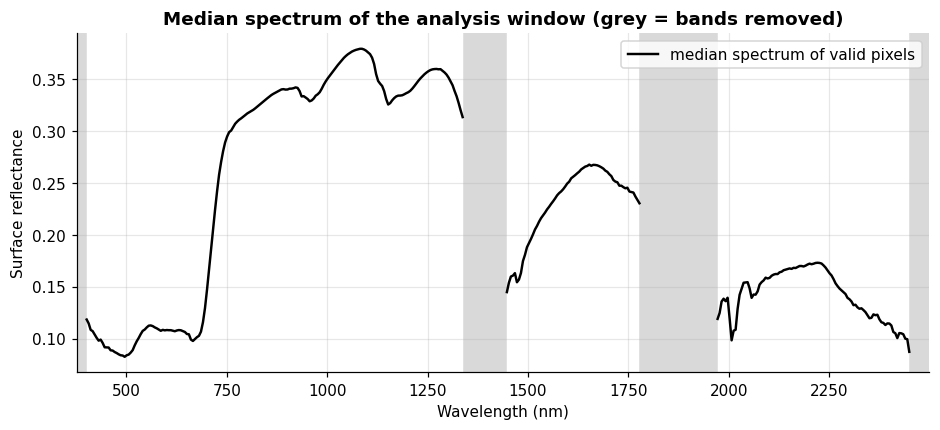

Extra steps beyond band and mask screening: none (no smoothing, continuum removal or normalisation), because the classifiers and indices work on the reflectance as delivered.


In [10]:
# Median spectrum of the analysis window; grey = bands removed (template section 4)
samp = np.flatnonzero(valid.ravel())[::25]
med = np.nanmedian(core.reshape(core.shape[0], -1)[:, samp], axis=1)
removed = ~keep
edges = np.flatnonzero(np.diff(np.r_[0, removed.astype(int), 0]))
fig, ax = plt.subplots(figsize=(10, 4))
for a_, b_ in zip(edges[::2], edges[1::2]):
    ax.axvspan(wl_all[a_] - 2.5, wl_all[b_ - 1] + 2.5, color="0.85", zorder=0)
gap_med = np.flatnonzero(np.diff(wl) > 15)
ax.plot(np.insert(wl.astype(float), gap_med + 1, np.nan), np.insert(med.astype(float), gap_med + 1, np.nan), color="k", lw=1.6, label="median spectrum of valid pixels")
ax.set(xlabel="Wavelength (nm)", ylabel="Surface reflectance", xlim=(wl_all.min(), wl_all.max()), title="Median spectrum of the analysis window (grey = bands removed)")
ax.legend(); ax.grid(alpha=0.3)
save(fig, "f03b_median_spectrum")
print(f"Extra steps beyond band and mask screening: none (no smoothing, continuum removal or normalisation), because the classifiers and indices work on the reflectance as delivered.")

## 5. Features: what the spectrum offers

Healthy leaves absorb red light (about 665 nm), reflect strongly in the near infrared (NIR, 750-1,300 nm) and show a steep rise between them, the **red edge**. Water in leaves and soil absorbs in the shortwave infrared (SWIR, around 1,650 nm). Different land covers shape these features differently, and a hyperspectral sensor samples them every 5 nm.

| Feature | Definition | Wavelengths | What it senses | Needs narrow bands? | Reference |
|---|---|---|---|---|---|
| **NDVI** | (NIR − Red) / (NIR + Red) | 860, 665 nm | green-leaf amount | no (any multispectral sensor) | Rouse et al. (1974) |
| **NDRE** | (NIR − RedEdge) / (NIR + RedEdge) | 790, 720 nm | chlorophyll, canopy density | yes (narrow red-edge bands) | red-edge chlorophyll link: Gitelson & Merzlyak (1994); band choice as in the course project template |
| **NDMI** | (NIR − SWIR) / (NIR + SWIR) | 860, 1,650 nm | canopy/soil water | partly | USGS, Normalized Difference Moisture Index; band choice as in the course project template |
| **REP** | red-edge position, four-point linear interpolation (Guyot et al. 1988) | 670, 700, 740, 780 nm | where the red edge sits (nm); shifts with chlorophyll | **yes** | Guyot, Baret & Major (1988) |

The band closest to each wavelength is used (the code refuses if none lies within 15 nm). Indices are exploratory descriptors, not calibrated measurements.

Bands actually used (requested nm -> band centre nm): {665: 665.9, 860: 861.3, 720: 721.0, 790: 791.1, 1650: 1647.7, 670: 670.9, 700: 700.9, 740: 741.0, 780: 781.1}


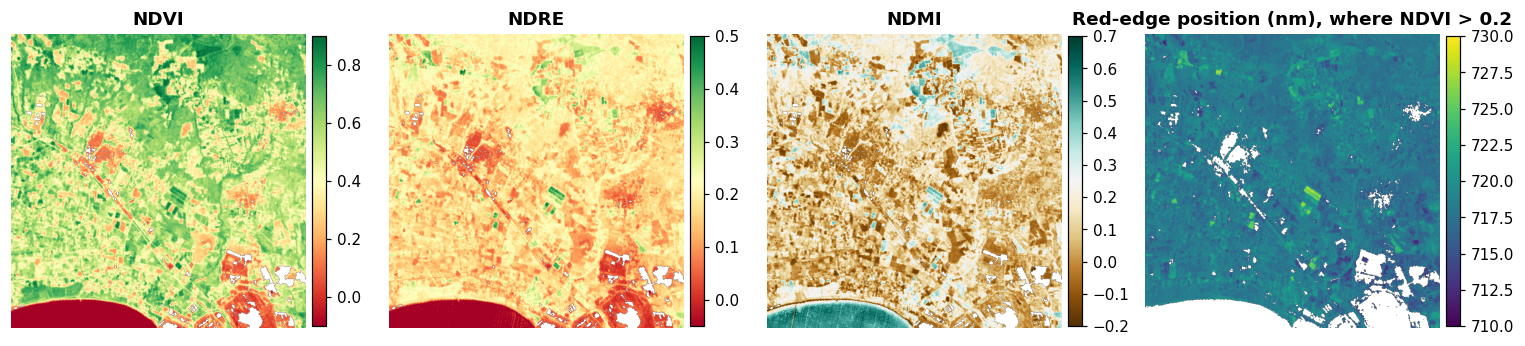

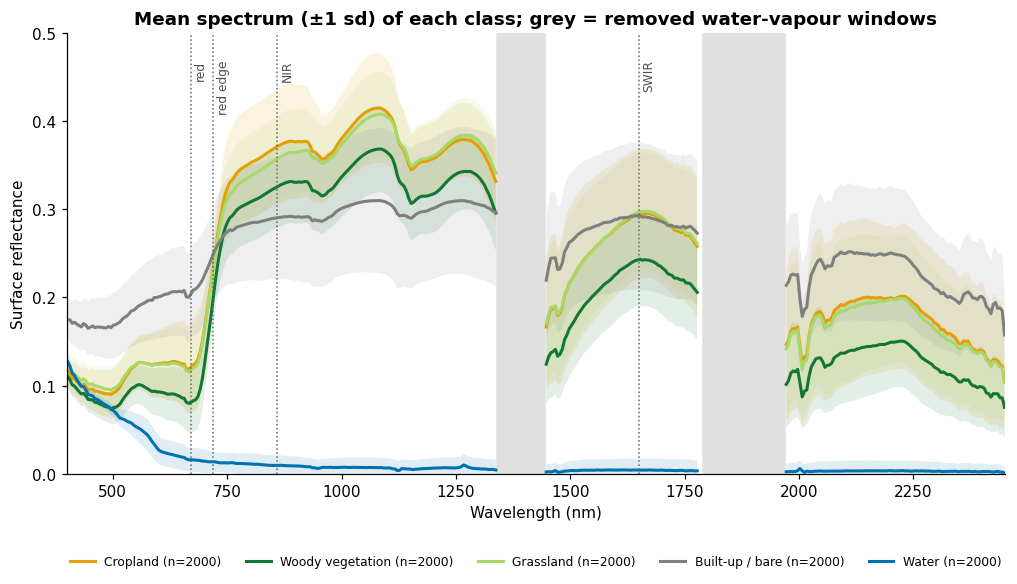

In [11]:
i = lambda nm: dm.nearest(wl, nm)
used = {nm: round(float(wl[i(nm)]), 1) for nm in (665, 860, 720, 790, 1650, 670, 700, 740, 780)}
print("Bands actually used (requested nm -> band centre nm):", used)

ndvi = dm.norm_diff(core[i(860)], core[i(665)])
ndre = dm.norm_diff(core[i(790)], core[i(720)])
ndmi = dm.norm_diff(core[i(860)], core[i(1650)])
rep = dm.red_edge_position(core, wl)
for a in (ndvi, ndre, ndmi, rep):
    a[~valid] = np.nan

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
rep_show = np.where(ndvi > 0.2, rep, np.nan)                  # the red edge only means something over vegetation
for ax, img, title, cmap, lim in zip(axes, (ndvi, ndre, ndmi, rep_show), ("NDVI", "NDRE", "NDMI", "Red-edge position (nm), where NDVI > 0.2"),
                                      ("RdYlGn", "RdYlGn", "BrBG", "viridis"), ((-0.1, 0.9), (-0.05, 0.5), (-0.2, 0.7), (710, 730))):
    im = ax.imshow(img, cmap=cmap, vmin=lim[0], vmax=lim[1]); ax.set_title(title); ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
save(fig, "f04_feature_maps")

# Mean spectrum of each reference class (pure, valid pixels), to see what a classifier can use
rng = np.random.default_rng(SEED)
gap_at = np.flatnonzero(np.diff(wl) > 15)                     # break the lines where bands were removed
wl_g = np.insert(wl.astype(float), gap_at + 1, np.nan)
gapped = lambda a: np.insert(np.asarray(a, float), gap_at + 1, np.nan)
fig, ax = plt.subplots(figsize=(11, 5.2))
for k, (name, colour) in enumerate(zip(dm.CLASS_NAMES, CLASS_COLOURS)):
    rr, cc = np.nonzero(valid & (pure == k))
    pick = rng.choice(len(rr), min(2000, len(rr)), replace=False)
    spec = core[:, rr[pick], cc[pick]]
    ax.plot(wl_g, gapped(spec.mean(1)), color=colour, lw=2, label=f"{name} (n={len(pick)})")
    ax.fill_between(wl_g, gapped(spec.mean(1) - spec.std(1)), gapped(spec.mean(1) + spec.std(1)), color=colour, alpha=0.12, lw=0)
for lo, hi in CONFIG["bad_ranges_nm"][1:3]:
    ax.axvspan(lo, hi, color="0.88", zorder=0)
for nm, lab in ((670, "red"), (720, "red edge"), (860, "NIR"), (1650, "SWIR")):
    ax.axvline(nm, color="0.4", ls=":", lw=1); ax.text(nm + 8, 0.47, lab, rotation=90, va="top", fontsize=8, color="0.3")
ax.set(xlabel="Wavelength (nm)", ylabel="Surface reflectance", xlim=(400, 2450), ylim=(0, 0.5),
       title="Mean spectrum (±1 sd) of each class; grey = removed water-vapour windows")
ax.legend(fontsize=8, ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
save(fig, "f05_class_spectra")

## 6. Method

We start with a **baseline** (a simple index threshold), then the main method. The difference between the two is our contribution. The main method is the five-class classifier on the full spectrum (6.3), compared with two intermediate feature sets.

### 6.0 Baseline

The baseline is the rule we planned at the start: pixels with **NDVI above 0.5 are "vegetation"**. Any multispectral sensor can apply it. Its binary and cropland scores are in section 7.

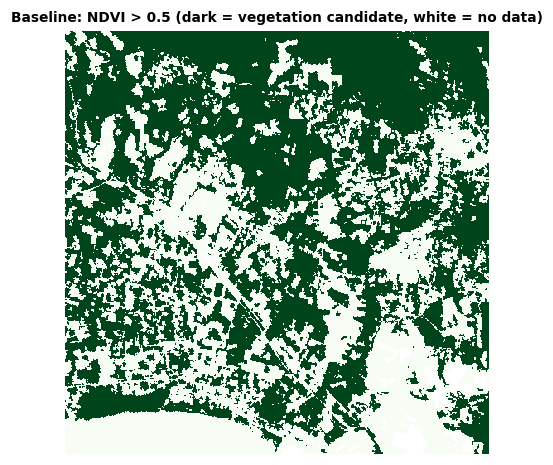

Baseline flags 131 km² of the 231 km² of valid area.


In [12]:
# Baseline: a threshold on NDVI
ok_b = valid & np.isfinite(ndvi)
baseline = np.full((H, W), np.nan, dtype="float32")
baseline[ok_b] = (ndvi[ok_b] > CONFIG["ndvi_baseline_threshold"]).astype("float32")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(baseline, cmap="Greens", vmin=0, vmax=1, interpolation="nearest")
ax.set_title(f"Baseline: NDVI > {CONFIG['ndvi_baseline_threshold']} (dark = vegetation candidate, white = no data)", fontsize=9); ax.axis("off")
save(fig, "f06a_baseline_ndvi")
px_km2 = (grid["pixel"] / 1000) ** 2
print(f"Baseline flags {np.nansum(baseline) * px_km2:.0f} km² of the {ok_b.sum() * px_km2:.0f} km² of valid area.")

### 6.1 Spatially independent train / validation / test split

Neighbouring pixels look alike, so a random pixel split would let the model "peek" at the test area and report inflated accuracy. Instead the crop is cut into **40 x 40-pixel blocks** and each *whole block* goes to exactly one of **train (50 %) / validation (20 %) / test (30 %)**. Blocks are drawn at random with a fixed seed and redrawn until every class has enough pixels in every split. The test blocks are **not used for any decision**: training uses the train blocks, model choice uses the validation blocks, and the test blocks are scored once.

Split drawn with seed 42. Usable reference pixels per class and split:


,train,validation,test
Cropland,21177,7462,10126
Woody vegetation,32510,14556,21398
Grassland,14668,6379,11262
Built-up / bare,8215,4358,2440
Water,5347,1280,3324
blocks,84,34,51


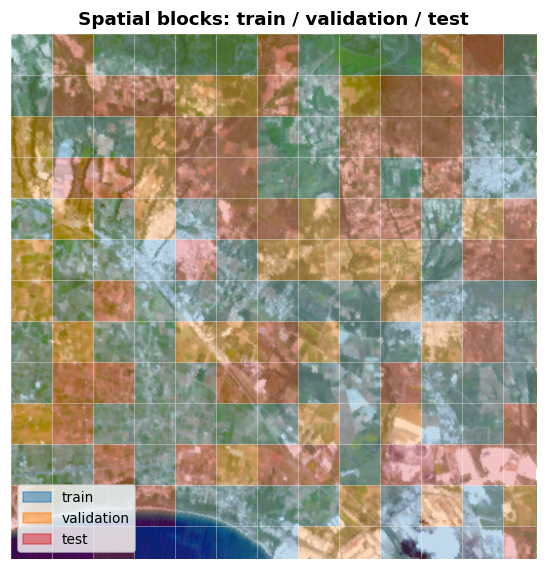

In [13]:
BLK = dm.block_ids((H, W), CONFIG["block_size"])
usable = valid & (pure >= 0)
split_img, split_seed = dm.assign_blocks(pure, usable, CONFIG["block_size"], CONFIG["split_fractions"], seed0=SEED)
SPLIT_NAMES = ["train", "validation", "test"]
tbl = pd.DataFrame({s: [int((usable & (split_img == j) & (pure == k)).sum()) for k in range(5)] for j, s in enumerate(SPLIT_NAMES)},
                   index=dm.CLASS_NAMES)
tbl.loc["blocks"] = [len(np.unique(BLK[split_img == j])) for j in range(3)]
print(f"Split drawn with seed {split_seed}. Usable reference pixels per class and split:")
display(tbl)

fig, ax = plt.subplots(figsize=(6.5, 6.2))
ax.imshow(rgb)
for j, (s, col) in enumerate(zip(SPLIT_NAMES, ("#1f77b4", "#ff7f0e", "#d62728"))):
    for b in np.unique(BLK[split_img == j]):
        r, c = np.argwhere(BLK == b)[0]
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), CONFIG["block_size"], CONFIG["block_size"], fill=True, fc=col, alpha=0.28, ec="white", lw=0.5))
ax.legend([Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in ("#1f77b4", "#ff7f0e", "#d62728")], SPLIT_NAMES, loc="lower left", fontsize=9)
ax.set_title("Spatial blocks: train / validation / test"); ax.axis("off")
save(fig, "f06_split_blocks")

### 6.2 Three competing feature sets, one fair comparison

All three see exactly the same pixels, the same labels and the same split. Only the *spectral information* differs:

| Feature set | What it represents | Number of features |
|---|---|---|
| **Four indices** | NDVI, NDRE, NDMI, REP | 4 |
| **Sentinel-2-like** | ten broad bands (B2-B8A, B11, B12) simulated from the narrow Tanager bands using Gaussian responses | 10 |
| **Full spectrum** | all retained narrow bands | one per retained band |

The Sentinel-2-like set stands in for "what a multispectral satellite would give". It is an **approximation** (real Sentinel-2 response curves are flatter, and real data would also differ in date, geometry and noise). We could not use real Sentinel-2 images: every scene within ±8 days of 30 April has 18-90 % cloud over this crop.

### 6.3 Models and how they are chosen

For each feature set we train a small, **pre-specified** set of standard classifiers on the training pixels (3,000 per class, drawn only from training blocks) and pick the one with the best **validation** macro-F1. Candidates: Random Forest; logistic regression (two regularisation strengths, C = 0.1 and 1); support-vector machine with an RBF kernel. Class weights are balanced so the rare classes count. Picking the best model separately for each feature set avoids handicapping a feature set with a model that suits it badly. The test set is not involved.

In [14]:
vy, vx = np.nonzero(valid)
flat = lambda img: img[valid]
y_all, split_all, blk_all = flat(pure), flat(split_img), flat(BLK)
labelled = y_all >= 0

X_full = core[:, valid].T.astype("float32")
X_s2 = dm.simulate_bands(X_full, wl)
IDX = np.column_stack([ndvi[valid], ndre[valid], ndmi[valid], rep[valid]])
IDX = np.where(np.isfinite(IDX), IDX, np.nanmedian(IDX, axis=0))           # rare undefined values -> column median
FEATURES = {"Four indices": IDX, "Sentinel-2-like": X_s2, "Full spectrum": X_full}
print({k: v.shape[1] for k, v in FEATURES.items()})

rng = np.random.default_rng(SEED)
train_idx = np.concatenate([rng.choice(np.flatnonzero(labelled & (split_all == 0) & (y_all == k)),
                                       min(CONFIG["train_per_class"], int((labelled & (split_all == 0) & (y_all == k)).sum())), replace=False)
                            for k in range(5)])
val_idx = np.flatnonzero(labelled & (split_all == 1))
test_idx = np.flatnonzero(labelled & (split_all == 2))
print(f"train {len(train_idx):,} | validation {len(val_idx):,} | test {len(test_idx):,} pixels")

def candidates():
    return {
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "Logistic regression C=0.1": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000, class_weight="balanced")),
        "Logistic regression C=1": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced")),
        "SVM (RBF) C=10": make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", class_weight="balanced")),
    }

fitted, rows = {}, []
for fname, F in FEATURES.items():
    for mname, model in candidates().items():
        t0 = time.time()
        model.fit(F[train_idx], y_all[train_idx])
        cm = np.bincount(y_all[val_idx] * 5 + model.predict(F[val_idx]), minlength=25).reshape(5, 5)
        m = dm.metrics_from_cm(cm)
        fitted[(fname, mname)] = model
        rows.append(dict(feature_set=fname, model=mname, val_macro_F1=m["macro_F1"], val_OA=m["OA"], seconds=time.time() - t0))
sel_tbl = pd.DataFrame(rows)
sel_tbl["selected"] = sel_tbl.groupby("feature_set")["val_macro_F1"].transform("max") == sel_tbl["val_macro_F1"]
display(sel_tbl.round(3))
SELECTED = {r.feature_set: r.model for r in sel_tbl[sel_tbl.selected].itertuples()}
print("Selected on validation macro-F1:", SELECTED)
sel_tbl.to_csv(VAL / "model_selection_validation.csv", index=False)

{'Four indices': 4, 'Sentinel-2-like': 10, 'Full spectrum': 352}
train 15,000 | validation 34,035 | test 48,550 pixels


,feature_set,model,val_macro_F1,val_OA,seconds,selected
0,Four indices,Random Forest,0.710,0.651,12.922,False
1,Four indices,Logistic regression C=0.1,0.664,0.613,0.214,False
2,Four indices,Logistic regression C=1,0.684,0.631,0.442,False
3,Four indices,SVM (RBF) C=10,0.715,0.667,24.067,True
4,Sentinel-2-like,Random Forest,0.771,0.720,17.492,False
5,Sentinel-2-like,Logistic regression C=0.1,0.734,0.664,0.259,False
6,Sentinel-2-like,Logistic regression C=1,0.742,0.675,0.599,False
7,Sentinel-2-like,SVM (RBF) C=10,0.781,0.730,15.881,True
8,Full spectrum,Random Forest,0.794,0.746,86.008,False
9,Full spectrum,Logistic regression C=0.1,0.829,0.794,29.610,False


Selected on validation macro-F1: {'Four indices': 'SVM (RBF) C=10', 'Sentinel-2-like': 'SVM (RBF) C=10', 'Full spectrum': 'Logistic regression C=1'}


## 7. Validation

Now the **test blocks**, which no model has been trained on and no model choice has used, are scored once.

> **Development note (for transparency).** An early exploratory run of this workflow, with a single Random Forest per feature set, printed scores for the test split. We then widened the candidate list (adding logistic regression and SVM), raised the training size to 3,000 pixels per class, and fixed the settings above using **validation** scores only. The final models were never selected by test scores, but we cannot claim we never saw a test number during development. Rows of every confusion matrix are the *reference* class and columns the *predicted* class. We report overall accuracy (OA), macro-F1 (the average F1 over the five classes, so rare classes count as much as common ones), per-class precision (user's accuracy) and recall (producer's accuracy), and **95 % confidence intervals from a block bootstrap**: test blocks are resampled with replacement, which respects the fact that pixels inside a block are not independent. All models use the *same* resampled blocks, so differences between models are properly paired.

,features,model (chosen on validation),OA [95% CI],macro-F1 [95% CI],cropland F1 [95% CI]
feature set,,,,,
Four indices,4,SVM (RBF) C=10,"0.661 [0.613, 0.709]","0.700 [0.644, 0.733]","0.478 [0.413, 0.546]"
Sentinel-2-like,10,SVM (RBF) C=10,"0.723 [0.686, 0.762]","0.771 [0.732, 0.792]","0.606 [0.547, 0.651]"
Full spectrum,352,Logistic regression C=1,"0.790 [0.758, 0.821]","0.823 [0.793, 0.840]","0.699 [0.654, 0.737]"


Test pixels: 48,550 in 51 blocks; bootstrap replicates: 1000


,comparison,metric,difference,95% CI,CI excludes 0
0,Full spectrum minus Sentinel-2-like,macro-F1,0.052,"[0.039, 0.071]",True
1,Full spectrum minus Sentinel-2-like,cropland F1,0.093,"[0.061, 0.134]",True
2,Full spectrum minus Four indices,macro-F1,0.123,"[0.098, 0.158]",True
3,Full spectrum minus Four indices,cropland F1,0.221,"[0.159, 0.288]",True
4,Sentinel-2-like minus Four indices,macro-F1,0.071,"[0.048, 0.098]",True
5,Sentinel-2-like minus Four indices,cropland F1,0.128,"[0.061, 0.195]",True


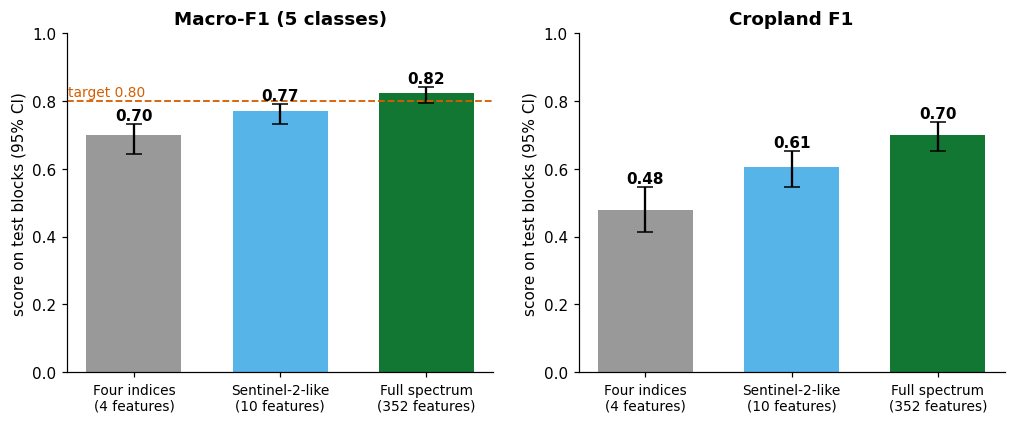

In [15]:
y_te, blk_te = y_all[test_idx], blk_all[test_idx]
pred_te = {f: fitted[(f, SELECTED[f])].predict(FEATURES[f][test_idx]) for f in FEATURES}

bcm = {}
for f in FEATURES:
    bcm[f], block_list = dm.block_confusions(y_te, pred_te[f], blk_te, 5)
draws = dm.bootstrap_draws(len(block_list), CONFIG["n_boot"], seed=SEED)
boot = {f: dm.metrics_from_cm(dm.boot_cm(bcm[f], draws)) for f in FEATURES}
point = {f: dm.metrics_from_cm(bcm[f].sum(0)) for f in FEATURES}

def fmt(p, b):
    lo, hi = dm.ci95(b)
    return f"{p:.3f} [{lo:.3f}, {hi:.3f}]"

res = pd.DataFrame({
    "feature set": list(FEATURES),
    "features": [FEATURES[f].shape[1] for f in FEATURES],
    "model (chosen on validation)": [SELECTED[f] for f in FEATURES],
    "OA [95% CI]": [fmt(point[f]["OA"], boot[f]["OA"]) for f in FEATURES],
    "macro-F1 [95% CI]": [fmt(point[f]["macro_F1"], boot[f]["macro_F1"]) for f in FEATURES],
    "cropland F1 [95% CI]": [fmt(point[f]["F1"][0], boot[f]["F1"][:, 0]) for f in FEATURES],
})
display(res.set_index("feature set"))
print(f"Test pixels: {len(test_idx):,} in {len(block_list)} blocks; bootstrap replicates: {CONFIG['n_boot']}")
res.to_csv(VAL / "test_metrics_multiclass.csv", index=False)

# Paired differences between feature sets
pairs = [("Full spectrum", "Sentinel-2-like"), ("Full spectrum", "Four indices"), ("Sentinel-2-like", "Four indices")]
diff_rows = []
for a, b in pairs:
    for label, pa, pb, ba, bb in (("macro-F1", point[a]["macro_F1"], point[b]["macro_F1"], boot[a]["macro_F1"], boot[b]["macro_F1"]),
                                  ("cropland F1", point[a]["F1"][0], point[b]["F1"][0], boot[a]["F1"][:, 0], boot[b]["F1"][:, 0])):
        d = ba - bb
        lo, hi = dm.ci95(d)
        diff_rows.append({"comparison": f"{a} minus {b}", "metric": label, "difference": round(pa - pb, 3),
                          "95% CI": f"[{lo:.3f}, {hi:.3f}]", "CI excludes 0": bool(lo > 0 or hi < 0)})
diff_tbl = pd.DataFrame(diff_rows)
display(diff_tbl)
diff_tbl.to_csv(VAL / "paired_differences.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cols = ["#999999", "#56B4E9", "#117733"]
for ax, (title, getp, getb) in zip(axes, (("Macro-F1 (5 classes)", lambda f: point[f]["macro_F1"], lambda f: boot[f]["macro_F1"]),
                                           ("Cropland F1", lambda f: point[f]["F1"][0], lambda f: boot[f]["F1"][:, 0]))):
    for j, f in enumerate(FEATURES):
        lo, hi = dm.ci95(getb(f))
        ax.bar(j, getp(f), color=cols[j], width=0.65)
        ax.errorbar(j, getp(f), yerr=[[getp(f) - lo], [hi - getp(f)]], color="k", capsize=5, lw=1.5)
        ax.text(j, hi + 0.012, f"{getp(f):.2f}", ha="center", fontsize=10, fontweight="bold")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{f}\n({FEATURES[f].shape[1]} features)" for f in FEATURES], fontsize=9)
    ax.set_ylim(0, 1); ax.set_title(title); ax.set_ylabel("score on test blocks (95% CI)")
    if "Macro" in title:
        ax.axhline(TARGET, color="#D55E00", ls="--", lw=1.2); ax.text(-0.45, TARGET + 0.015, f"target {TARGET:.2f}", color="#D55E00", ha="left", fontsize=9)
save(fig, "f07_results_comparison")

### 7.1 Per-class results and confusion matrices

,reference pixels,precision (user's),recall (producer's),F1,IoU,F1 Sentinel-2-like,F1 Four indices
class,,,,,,,
Cropland,10126,0.709,0.689,0.699,0.537,0.606,0.478
Woody vegetation,21398,0.909,0.807,0.855,0.747,0.788,0.774
Grassland,11262,0.626,0.758,0.686,0.522,0.619,0.501
Built-up / bare,2440,0.831,0.936,0.880,0.786,0.841,0.750
Water,3324,0.993,1.000,0.996,0.993,0.999,0.997


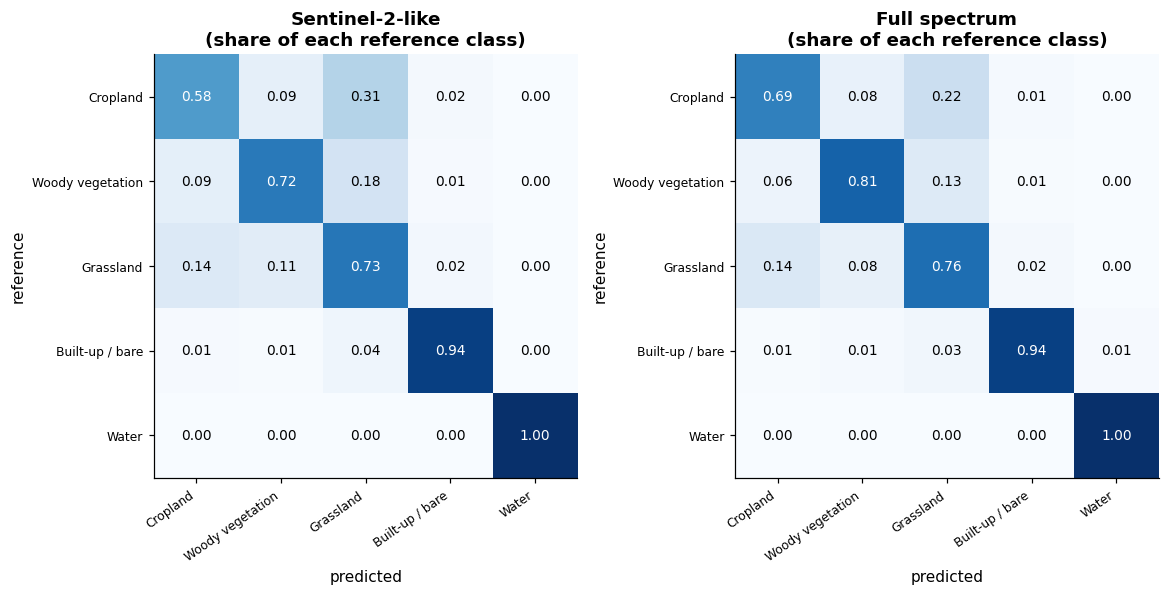

In [16]:
CM_FULL = bcm["Full spectrum"].sum(0)
mfull = point["Full spectrum"]
per_class = pd.DataFrame({"class": dm.CLASS_NAMES,
                          "reference pixels": CM_FULL.sum(1).astype(int),
                          "precision (user's)": mfull["precision"], "recall (producer's)": mfull["recall"],
                          "F1": mfull["F1"], "IoU": mfull["IoU"]}).set_index("class")
for j, f in enumerate(["Sentinel-2-like", "Four indices"]):
    per_class[f"F1 {f}"] = point[f]["F1"]
display(per_class.round(3))
per_class.round(4).to_csv(VAL / "per_class_metrics_test.csv")
for f in FEATURES:
    pd.DataFrame(bcm[f].sum(0).astype(int), index=[f"ref: {c}" for c in dm.CLASS_NAMES],
                 columns=[f"pred: {c}" for c in dm.CLASS_NAMES]).to_csv(VAL / f"confusion_matrix_{f.replace(' ', '_').replace('-', '')}.csv")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, f in zip(axes, ("Sentinel-2-like", "Full spectrum")):
    cmn = bcm[f].sum(0) / bcm[f].sum(0).sum(1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for r in range(5):
        for c in range(5):
            ax.text(c, r, f"{cmn[r, c]:.2f}", ha="center", va="center", color="white" if cmn[r, c] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels(dm.CLASS_NAMES, rotation=35, ha="right", fontsize=8); ax.set_yticklabels(dm.CLASS_NAMES, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("reference"); ax.set_title(f"{f}\n(share of each reference class)")
fig.savefig(VAL / "confusion_matrices.png", bbox_inches="tight")      # also kept next to the validation tables
save(fig, "f08_confusion_matrices")

### 7.2 The baseline: how good is an NDVI threshold at finding vegetation?

This is the **binary** question *vegetation vs not vegetation* (vegetation = cropland + woody + grassland). We compare:

* **NDVI > 0.5**, the threshold from our first canvas, chosen *before* looking at any data;
* **NDVI > t\***, a threshold tuned fairly: the value that maximises the vegetation F1 on the **training** pixels only (so the baseline gets a fair chance);
* the three feature sets, with their five-class predictions merged into vegetation / non-vegetation.

In [17]:
veg = lambda a: np.isin(a, dm.VEGETATION).astype(int)
ndvi_v = ndvi[valid]
grid_t = np.round(np.arange(0.05, 0.91, 0.01), 2)
def veg_f1(pred, ref):
    tp = (pred & ref).sum(); return 2 * tp / max(2 * tp + (pred & ~ref).sum() + (~pred & ref).sum(), 1)
t_star = float(grid_t[np.argmax([veg_f1(ndvi_v[train_idx] > t, veg(y_all[train_idx]).astype(bool)) for t in grid_t])])
print(f"Threshold tuned on training pixels only: NDVI > {t_star:.2f}")

yb = veg(y_te)
bin_pred = {"NDVI > 0.5 (as planned)": (ndvi_v[test_idx] > CONFIG["ndvi_baseline_threshold"]).astype(int),
            f"NDVI > {t_star:.2f} (tuned on train)": (ndvi_v[test_idx] > t_star).astype(int)}
for f in FEATURES:
    bin_pred[f"{f} (merged classes)"] = veg(pred_te[f])
bbcm = {n: dm.block_confusions(yb, p, blk_te, 2)[0] for n, p in bin_pred.items()}
bboot = {n: dm.metrics_from_cm(dm.boot_cm(b, draws)) for n, b in bbcm.items()}
bpt = {n: dm.metrics_from_cm(b.sum(0)) for n, b in bbcm.items()}
bin_tbl = pd.DataFrame({
    "method": list(bin_pred),
    "OA [95% CI]": [fmt(bpt[n]["OA"], bboot[n]["OA"]) for n in bin_pred],
    "vegetation F1 [95% CI]": [fmt(bpt[n]["F1"][1], bboot[n]["F1"][:, 1]) for n in bin_pred],
    "vegetation recall": [round(float(bpt[n]["recall"][1]), 3) for n in bin_pred],
    "vegetation precision": [round(float(bpt[n]["precision"][1]), 3) for n in bin_pred]}).set_index("method")
display(bin_tbl)
bin_tbl.to_csv(VAL / "test_metrics_vegetation_binary.csv")

sens = pd.DataFrame({"NDVI threshold": CONFIG["sensitivity_thresholds"],
                     "OA on test": [float(((ndvi_v[test_idx] > t).astype(int) == yb).mean()) for t in CONFIG["sensitivity_thresholds"]],
                     "vegetation F1 on test": [veg_f1(ndvi_v[test_idx] > t, yb.astype(bool)) for t in CONFIG["sensitivity_thresholds"]]}).round(3)
display(sens)

Threshold tuned on training pixels only: NDVI > 0.25


,OA [95% CI],vegetation F1 [95% CI],vegetation recall,vegetation precision
method,,,,
NDVI > 0.5 (as planned),"0.736 [0.688, 0.783]","0.824 [0.787, 0.859]",0.701,0.999
NDVI > 0.25 (tuned on train),"0.966 [0.953, 0.977]","0.981 [0.973, 0.987]",0.977,0.985
Four indices (merged classes),"0.970 [0.953, 0.984]","0.983 [0.972, 0.991]",0.971,0.995
Sentinel-2-like (merged classes),"0.982 [0.974, 0.990]","0.990 [0.985, 0.994]",0.983,0.996
Full spectrum (merged classes),"0.988 [0.981, 0.993]","0.993 [0.989, 0.996]",0.989,0.997


,NDVI threshold,OA on test,vegetation F1 on test
0,0.2,0.973,0.985
1,0.3,0.944,0.967
2,0.4,0.867,0.919
3,0.5,0.736,0.824
4,0.6,0.530,0.636


### 7.3 Robustness: how much does mixed-pixel label noise matter?

Pixels at the edge of a field or forest can still be "pure" in WorldCover yet mixed in reality. As a sensitivity check we re-score only **interior** test pixels, whose eight neighbours carry the same reference class. A large gain would mean that part of the error is boundary noise rather than model weakness.

In [18]:
interior = (ndi.minimum_filter(pure, size=3, mode="nearest") == ndi.maximum_filter(pure, size=3, mode="nearest")) & (pure >= 0)
int_te = interior[valid][test_idx]

def cms_subset(mask, pred):
    cm_s, ub = dm.block_confusions(y_te[mask], pred[mask], blk_te[mask], 5)
    out = np.zeros((len(block_list), 5, 5)); out[np.searchsorted(block_list, ub)] = cm_s
    return out

rows, interior_f1 = [], {}
for f in FEATURES:
    b_all = dm.metrics_from_cm(bcm[f].sum(0))
    sub = cms_subset(int_te, pred_te[f])
    b_int = dm.metrics_from_cm(sub.sum(0)); bi = dm.metrics_from_cm(dm.boot_cm(sub, draws)); interior_f1[f] = float(b_int["macro_F1"])
    rows.append({"feature set": f, "macro-F1, all test pixels": round(float(b_all["macro_F1"]), 3),
                 "macro-F1, interior pixels only [95% CI]": fmt(b_int["macro_F1"], bi["macro_F1"]), "interior share of test pixels": round(float(int_te.mean()), 3)})
robust = pd.DataFrame(rows).set_index("feature set"); display(robust)
robust.to_csv(VAL / "robustness_interior_pixels.csv")

,"macro-F1, all test pixels","macro-F1, interior pixels only [95% CI]",interior share of test pixels
feature set,,,
Four indices,0.700,"0.752 [0.651, 0.796]",0.324
Sentinel-2-like,0.771,"0.847 [0.782, 0.875]",0.324
Full spectrum,0.823,"0.898 [0.847, 0.919]",0.324


### 7.4 Is the result an accident of one random split?

The split above is one random draw of blocks. To check that the ranking of the three feature sets does not depend on that draw, we repeat the whole comparison on **five different random block splits**. To keep this affordable every feature set uses the same fast classifier (Random Forest) here, so the numbers are not identical to the main table; the question is only whether the *ordering* holds.

In [19]:
stab = []
for s in range(5):
    sp, used = dm.assign_blocks(pure, usable, CONFIG["block_size"], CONFIG["split_fractions"], seed0=SEED + 1000 * (s + 1))
    sp_v = sp[valid]
    r_ = np.random.default_rng(SEED + s)
    tr = np.concatenate([r_.choice(np.flatnonzero(labelled & (sp_v == 0) & (y_all == k)),
                                   min(CONFIG["train_per_class"], int((labelled & (sp_v == 0) & (y_all == k)).sum())), replace=False) for k in range(5)])
    te = np.flatnonzero(labelled & (sp_v == 2))
    row = {"split seed": used}
    for f, F in FEATURES.items():
        m = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(F[tr], y_all[tr])
        cm = np.bincount(y_all[te] * 5 + m.predict(F[te]), minlength=25).reshape(5, 5)
        row[f] = float(dm.metrics_from_cm(cm)["macro_F1"])
    stab.append(row)
stab = pd.DataFrame(stab).set_index("split seed")
stab["Full > S2-like > indices"] = (stab["Full spectrum"] > stab["Sentinel-2-like"]) & (stab["Sentinel-2-like"] > stab["Four indices"])
display(stab.round(3))
stab.round(4).to_csv(VAL / "split_stability_macroF1_random_forest.csv")
display(Markdown(f"The ordering full spectrum > Sentinel-2-like > four indices held in **{int(stab['Full > S2-like > indices'].sum())} of 5** random block splits. "
                 f"Mean macro-F1 (Random Forest): full {stab['Full spectrum'].mean():.3f}, Sentinel-2-like {stab['Sentinel-2-like'].mean():.3f}, four indices {stab['Four indices'].mean():.3f}."))

,Four indices,Sentinel-2-like,Full spectrum,Full > S2-like > indices
split seed,,,,
1042,0.689,0.763,0.781,True
2042,0.706,0.757,0.785,True
3042,0.707,0.766,0.789,True
4042,0.708,0.772,0.783,True
5042,0.699,0.767,0.793,True


The ordering full spectrum > Sentinel-2-like > four indices held in **5 of 5** random block splits. Mean macro-F1 (Random Forest): full 0.786, Sentinel-2-like 0.765, four indices 0.702.

### 7.5 Where does it fail, and why?


The map below marks every test pixel of the full-spectrum model as correct or wrong. The confusion matrices above show *which* classes are mistaken for which. The physical reasons are discussed in the next cell after the figure.

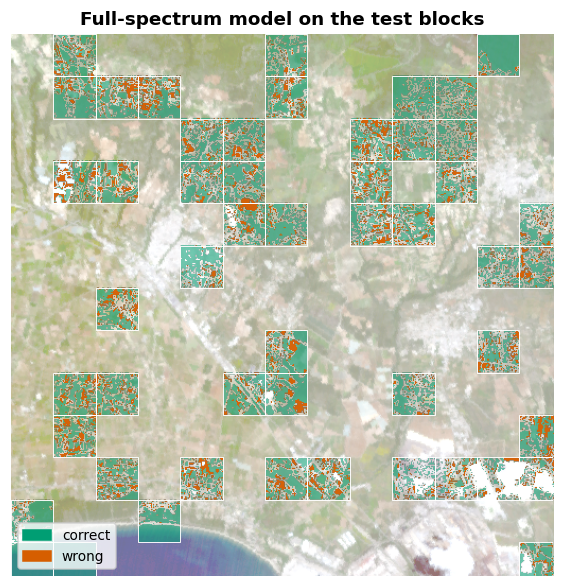

**Largest confusions (share of the reference class, full spectrum):** Cropland → predicted Grassland: 22%; Grassland → predicted Cropland: 14%; Woody vegetation → predicted Grassland: 13%; Grassland → predicted Woody vegetation: 8%

In [20]:
rows_t, cols_t = vy[test_idx], vx[test_idx]
wrong = pred_te["Full spectrum"] != y_te
fig, ax = plt.subplots(figsize=(7, 6.4))
ax.imshow(rgb, alpha=0.55)
ov = np.zeros((H, W, 4))
ov[rows_t[~wrong], cols_t[~wrong]] = (0.0, 0.62, 0.45, 0.55)
ov[rows_t[wrong], cols_t[wrong]] = (0.84, 0.37, 0.0, 0.95)
ax.imshow(ov)
for b in block_list:
    r, c = np.argwhere(BLK == b)[0]
    ax.add_patch(Rectangle((c - 0.5, r - 0.5), CONFIG["block_size"], CONFIG["block_size"], fill=False, ec="white", lw=0.6))
ax.legend([Rectangle((0, 0), 1, 1, color=(0.0, 0.62, 0.45)), Rectangle((0, 0), 1, 1, color=(0.84, 0.37, 0.0))], ["correct", "wrong"], loc="lower left", fontsize=9)
ax.set_title("Full-spectrum model on the test blocks"); ax.axis("off")
save(fig, "f09_error_map")

conf_pairs = []
for r in range(5):
    for c in range(5):
        if r != c:
            conf_pairs.append((CM_FULL[r, c] / CM_FULL[r].sum(), dm.CLASS_NAMES[r], dm.CLASS_NAMES[c]))
top_conf = sorted(conf_pairs, reverse=True)[:4]
display(Markdown("**Largest confusions (share of the reference class, full spectrum):** " +
                 "; ".join(f"{a} → predicted {b}: {s:.0%}" for s, a, b in [(t[0], t[1], t[2]) for t in top_conf])))

In [21]:
cc = {(a, b): s for s, a, b in conf_pairs}
display(Markdown(
    f"**Why these errors? (interpretation, not proof)**\n"
    f"* *Cropland and grassland are the main confusion* (cropland predicted as grassland {cc[('Cropland', 'Grassland')]:.0%}; grassland predicted as cropland {cc[('Grassland', 'Cropland')]:.0%}). "
    f"In April both are green herbaceous canopies and their mean spectra almost coincide (figure f05). Fallow, young or grass-covered fields look like grassland, and the 2021 reference may label a field that has since changed use.\n"
    f"* *Woody vegetation predicted as grassland* ({cc[('Woody vegetation', 'Grassland')]:.0%}): sparse scrub and tree crops with grass between the trees are mixed pixels at 30 m.\n"
    f"* *Water and built-up/bare* are almost always right. For built-up this is partly because the brightest surfaces were removed by the cloud-mask false positives (section 4).\n"
    f"* *Edges and label noise.* On interior pixels macro-F1 rises from {point['Full spectrum']['macro_F1']:.2f} to {interior_f1['Full spectrum']:.2f}, so a visible part of the error sits at boundaries between covers and in label noise rather than in the model."))

**Why these errors? (interpretation, not proof)**
* *Cropland and grassland are the main confusion* (cropland predicted as grassland 22%; grassland predicted as cropland 14%). In April both are green herbaceous canopies and their mean spectra almost coincide (figure f05). Fallow, young or grass-covered fields look like grassland, and the 2021 reference may label a field that has since changed use.
* *Woody vegetation predicted as grassland* (13%): sparse scrub and tree crops with grass between the trees are mixed pixels at 30 m.
* *Water and built-up/bare* are almost always right. For built-up this is partly because the brightest surfaces were removed by the cloud-mask false positives (section 4).
* *Edges and label noise.* On interior pixels macro-F1 rises from 0.82 to 0.90, so a visible part of the error sits at boundaries between covers and in label noise rather than in the model.

## 8. Uncertainty and limitations

We communicate uncertainty in four complementary ways: (1) a per-pixel **NDVI uncertainty map** propagated from the sensor's own reflectance-uncertainty layer; (2) **confidence intervals** on every accuracy number (block bootstrap, above); (3) a per-pixel **model-confidence map** with a check that confidence really predicts correctness; (4) a **threshold-sensitivity** analysis of the vegetation area.

### 8.1 NDVI uncertainty from the reflectance-uncertainty layer

NDVI 1-sigma uncertainty: median 0.0051, 95th percentile 0.0065, max 0.045


,NDVI threshold,"area, certain (NDVI-σ > t) km²","area, nominal (NDVI > t) km²","area, possible (NDVI+σ > t) km²"
0,0.2,209.9,210.5,211.2
1,0.3,192.7,194.0,195.3
2,0.4,165.8,167.4,169.1
3,0.5,128.9,131.2,133.5
4,0.6,80.3,82.7,85.2


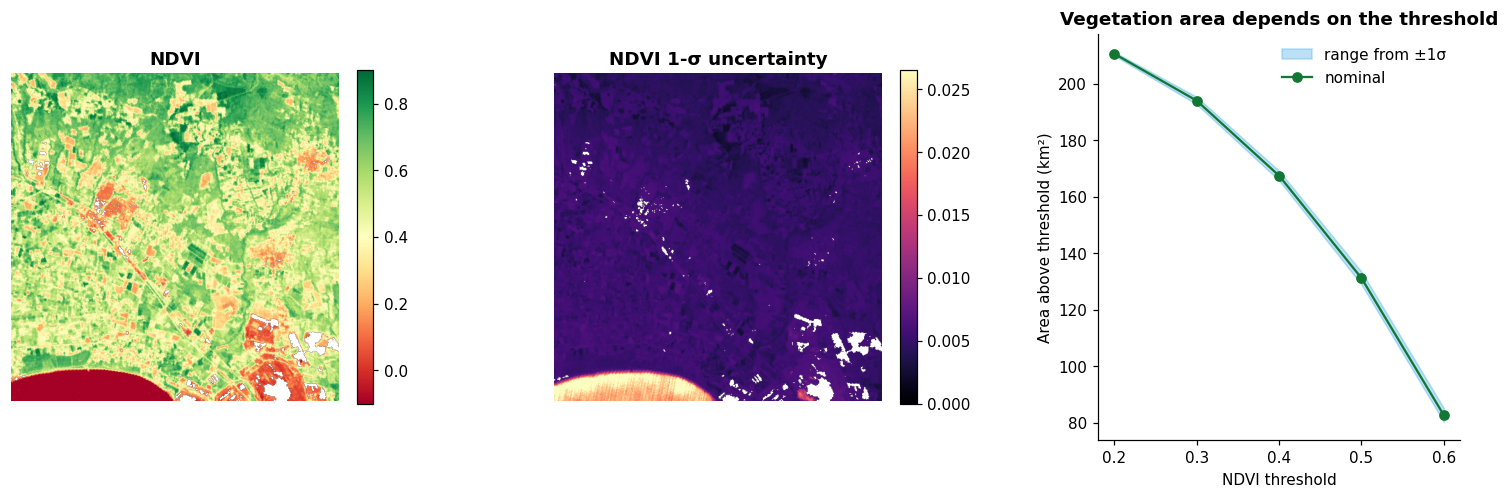

At the planned threshold of 0.5 the vegetation area is 131 km², and sensor uncertainty alone moves it only within 129-133 km². Moving the threshold from 0.5 to 0.4 changes it by 36 km². **The choice of threshold, not sensor noise, dominates the uncertainty of an NDVI-based area.** (NDVI uncertainty is largest over dark water, where reflectance is very low.)

In [22]:
orig = np.flatnonzero(keep)
r0, r1, c0, c1 = window
def unc_band(nm):
    a = h5[dm.UNCERTAINTY][int(orig[i(nm)]), r0:r1, c0:c1].astype("float32"); a[a <= -9000] = np.nan; return a
sig_red, sig_nir = unc_band(665), unc_band(860)
ndvi_sig = dm.ndvi_sigma(core[i(665)], core[i(860)], sig_red, sig_nir)
ndvi_sig[~valid | ~np.isfinite(ndvi)] = np.nan
print(f"NDVI 1-sigma uncertainty: median {np.nanmedian(ndvi_sig):.4f}, 95th percentile {np.nanpercentile(ndvi_sig, 95):.4f}, max {np.nanmax(ndvi_sig):.3f}")

lo_n, mid_n, hi_n = [], [], []
for t in CONFIG["sensitivity_thresholds"]:
    ok = valid & np.isfinite(ndvi) & np.isfinite(ndvi_sig)
    lo_n.append(int(((ndvi - ndvi_sig > t) & ok).sum())); mid_n.append(int(((ndvi > t) & ok).sum())); hi_n.append(int(((ndvi + ndvi_sig > t) & ok).sum()))
sens_area = pd.DataFrame({"NDVI threshold": CONFIG["sensitivity_thresholds"],
                          "area, certain (NDVI-σ > t) km²": np.array(lo_n) * 0.0009, "area, nominal (NDVI > t) km²": np.array(mid_n) * 0.0009,
                          "area, possible (NDVI+σ > t) km²": np.array(hi_n) * 0.0009}).round(1)
display(sens_area)
sens_area.to_csv(VAL / "ndvi_threshold_sensitivity_with_uncertainty.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"wspace": 0.5})
im = axes[0].imshow(ndvi, cmap="RdYlGn", vmin=-0.1, vmax=0.9); axes[0].set_title("NDVI"); fig.colorbar(im, ax=axes[0], fraction=0.046)
im = axes[1].imshow(ndvi_sig, cmap="magma", vmin=0, vmax=np.nanpercentile(ndvi_sig, 99)); axes[1].set_title("NDVI 1-σ uncertainty"); fig.colorbar(im, ax=axes[1], fraction=0.046)
for a in axes[:2]: a.axis("off")
ax = axes[2]; ts = CONFIG["sensitivity_thresholds"]
ax.fill_between(ts, np.array(lo_n) * 0.0009, np.array(hi_n) * 0.0009, color="#56B4E9", alpha=0.4, label="range from ±1σ")
ax.plot(ts, np.array(mid_n) * 0.0009, "o-", color="#117733", label="nominal")
ax.set(xlabel="NDVI threshold", ylabel="Area above threshold (km²)", title="Vegetation area depends on the threshold"); ax.legend(frameon=False)
save(fig, "f10_ndvi_uncertainty")
display(Markdown(
    f"At the planned threshold of 0.5 the vegetation area is {mid_n[3] * 0.0009:.0f} km², and sensor uncertainty alone moves it only within {lo_n[3] * 0.0009:.0f}-{hi_n[3] * 0.0009:.0f} km². "
    f"Moving the threshold from 0.5 to 0.4 changes it by {(mid_n[2] - mid_n[3]) * 0.0009:.0f} km². **The choice of threshold, not sensor noise, dominates the uncertainty of an NDVI-based area.** "
    f"(NDVI uncertainty is largest over dark water, where reflectance is very low.)"))

### 8.2 Model confidence: does it predict correctness?

For the chosen full-spectrum model every pixel gets a confidence (the highest predicted class probability). A useful confidence map should be *calibrated*: pixels with 80 % confidence should be right about 80 % of the time. We check that on the test blocks, using ten equal-sized confidence groups.

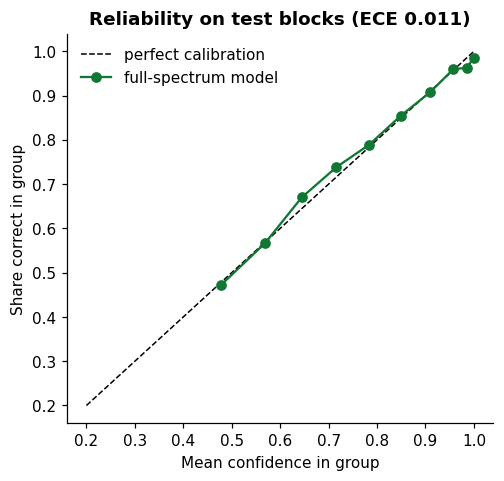

Expected calibration error: 0.011; accuracy in the most confident 10 %: 0.98, in the least confident 10 %: 0.47


In [23]:
def predict_with_confidence(model, F, batch=40000):
    labs, confs = [], []
    for s in range(0, len(F), batch):
        part = F[s:s + batch]
        if hasattr(model, "predict_proba"):
            p = model.predict_proba(part); labs.append(p.argmax(1)); confs.append(p.max(1))
        else:                                             # e.g. SVM: use the margin between the best two class scores
            d = model.decision_function(part); srt = np.sort(d, 1); labs.append(d.argmax(1)); confs.append(srt[:, -1] - srt[:, -2])
    return np.concatenate(labs), np.concatenate(confs).astype("float32")

main_model = fitted[("Full spectrum", SELECTED["Full spectrum"])]
has_proba = hasattr(main_model, "predict_proba")
pred_te_chk, conf_te = predict_with_confidence(main_model, X_full[test_idx])
assert (pred_te_chk == pred_te["Full spectrum"]).all()
correct = (pred_te_chk == y_te)

if has_proba:
    edges = np.quantile(conf_te, np.linspace(0, 1, 11)); edges[-1] += 1e-9
    gi = np.clip(np.digitize(conf_te, edges) - 1, 0, 9)
    cal = pd.DataFrame({"mean confidence": [conf_te[gi == g].mean() for g in range(10)], "accuracy": [correct[gi == g].mean() for g in range(10)],
                        "pixels": [int((gi == g).sum()) for g in range(10)]})
    ece = float(np.sum(cal["pixels"] / cal["pixels"].sum() * (cal["accuracy"] - cal["mean confidence"]).abs()))
    fig, ax = plt.subplots(figsize=(5, 4.6))
    ax.plot([0.2, 1], [0.2, 1], "k--", lw=1, label="perfect calibration")
    ax.plot(cal["mean confidence"], cal["accuracy"], "o-", color="#117733", label="full-spectrum model")
    ax.set(xlabel="Mean confidence in group", ylabel="Share correct in group", title=f"Reliability on test blocks (ECE {ece:.3f})"); ax.legend(frameon=False)
    save(fig, "f11_reliability"); cal.round(3).to_csv(VAL / "confidence_calibration.csv", index=False)
    print(f"Expected calibration error: {ece:.3f}; accuracy in the most confident 10 %: {cal['accuracy'].iloc[-1]:.2f}, in the least confident 10 %: {cal['accuracy'].iloc[0]:.2f}")
else:
    ece = np.nan
    print("Selected model has no probabilities; confidence = margin between the two best class scores (not calibrated).")

### 8.3 Limitations and how they affect the user

| Limitation | How it affects the user |
|---|---|
| **Reference = WorldCover 2021, not field truth** (about 77 % overall accuracy worldwide, four years older than the scene; crops rotate, so the cropland label is the noisiest) | The accuracy numbers mean *agreement with WorldCover*. Real accuracy on the ground could be higher or lower, so the map should guide inspections, not replace them. |
| **One date, one scene, one 236 km² crop** | Crop spectra change with the season, so results may not transfer to other dates or regions, and the map says nothing about change. |
| **Cropland is a land-cover class, not crop type, health or yield** | The map must not be used to judge what is grown, whether crops are stressed, or how much they yield. |
| **Sentinel-2-like bands are simulated** from the same scene | The advantage of Tanager over *real* Sentinel-2 data could be smaller or larger than +0.05 macro-F1. |
| **Beta cloud/cirrus masks give false positives over very bright surfaces, and 30 m pixels mix covers** (olive groves with grass, field edges) | The brightest built-up pixels are missing and built-up accuracy is probably optimistic; edge pixels are less reliable (interior-pixel check, section 7.3). |
| **The NDVI error propagation assumes independent band errors, and the test set has only about 50 blocks** | The NDVI uncertainty may be overstated, and confidence intervals on differences between feature sets are wide. |

## 9. Product output

For the user the product is a set of **georeferenced layers** (Cloud-Optimised GeoTIFFs in UTM 33N) plus a short report and a ranked table of inspection cells. We now apply the validated full-spectrum model to every valid pixel in the crop.

COG check passed: EPSG:32633 (512, 512) bounds [674520, 4486140, 689880, 4501500]
Class legend: 0 = Cropland, 1 = Woody vegetation, 2 = Grassland, 3 = Built-up / bare, 4 = Water


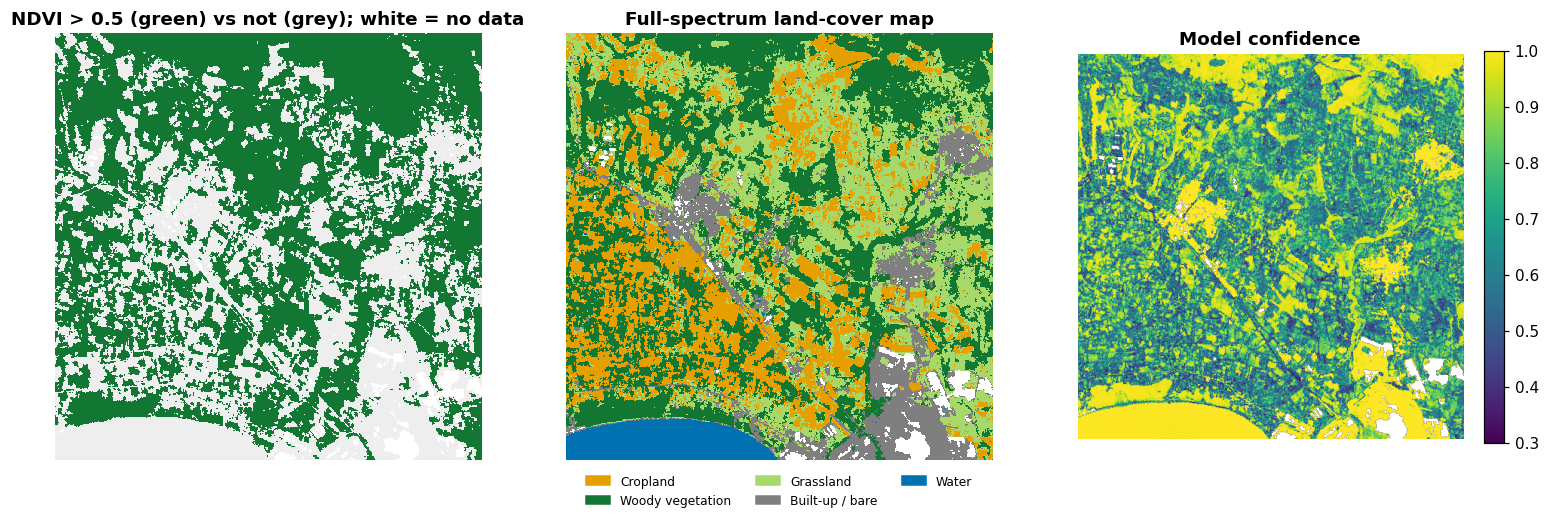

In [24]:
pred_all, conf_all = predict_with_confidence(main_model, X_full)
class_map = np.full((H, W), 255, dtype="uint8"); class_map[valid] = pred_all
conf_map = np.full((H, W), np.nan, dtype="float32"); conf_map[valid] = conf_all
baseline_05 = np.full((H, W), 255, dtype="uint8"); baseline_05[valid & np.isfinite(ndvi)] = (ndvi[valid & np.isfinite(ndvi)] > CONFIG["ndvi_baseline_threshold"]).astype("uint8")
EPSG, tf = grid["epsg"], transform
layers = {
    "Project_Demeter_landcover_COG.tif": (class_map, 255, "land cover class 0-4 (full-spectrum model); 255 = no data"),
    "Project_Demeter_confidence_COG.tif": (conf_map, np.nan, "model confidence (max class probability)"),
    "Project_Demeter_NDVI_COG.tif": (ndvi.astype("float32"), np.nan, "NDVI (860/665 nm)"),
    "Project_Demeter_NDVI_sigma_COG.tif": (ndvi_sig.astype("float32"), np.nan, "NDVI 1-sigma uncertainty"),
    "Project_Demeter_NDVI_gt_0.5_COG.tif": (baseline_05, 255, "NDVI > 0.5 vegetation candidates; 255 = no data"),
}
for name, (arr, nod, desc) in layers.items():
    dm.save_cog(OUT / name, arr, tf, EPSG, nod, desc)
# round-trip check: the file reads back identical and is georeferenced
with rasterio.open(OUT / "Project_Demeter_landcover_COG.tif") as ds:
    assert ds.crs.to_epsg() == EPSG and ds.shape == (H, W) and (ds.read(1) == class_map).all()
    print("COG check passed:", ds.crs, ds.shape, "bounds", [round(b) for b in ds.bounds])
print("Class legend: " + ", ".join(f"{k} = {n}" for k, n in enumerate(dm.CLASS_NAMES)))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
b = np.ma.masked_equal(baseline_05, 255)
axes[0].imshow(b, cmap=ListedColormap(["#EEEEEE", "#117733"]), vmin=0, vmax=1, interpolation="nearest"); axes[0].set_title("NDVI > 0.5 (green) vs not (grey); white = no data")
lc = np.ma.masked_equal(class_map, 255)
axes[1].imshow(lc, cmap=ListedColormap(CLASS_COLOURS), vmin=-0.5, vmax=4.5, interpolation="nearest"); axes[1].set_title("Full-spectrum land-cover map")
axes[1].legend([Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLOURS], dm.CLASS_NAMES, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, fontsize=8, frameon=False)
im = axes[2].imshow(conf_map, cmap="viridis", vmin=0.3, vmax=1); axes[2].set_title("Model confidence"); fig.colorbar(im, ax=axes[2], fraction=0.046)
for a in axes: a.axis("off")
save(fig, "f12_product_maps")

### 9.1 Impact: how much inspection area does the full-spectrum map save?

The question from the user's side: *if I only care about cropland, how much land does each map ask me to look at?* The numbers use pixel areas (900 m²) from the projected grid. The "share that is really cropland" figures come from the **reference labels** in the test blocks, not from our own map, so they are independent of the model.

In [25]:
PIX_KM2 = (grid["pixel"] / 1000) ** 2
a_ndvi05 = float((baseline_05 == 1).sum() * PIX_KM2)
a_ndvi_t = float(((ndvi > t_star) & valid).sum() * PIX_KM2)
a_crop_map = float((class_map == 0).sum() * PIX_KM2)
a_valid = float(valid.sum() * PIX_KM2)
a_crop_wc = float(((modal == 40) & valid).sum() * PIX_KM2)

m05 = (ndvi_v[test_idx] > 0.5)
share_crop_in_ndvi05 = float((y_te[m05] == 0).mean())
crop_recall_ndvi05 = float((m05 & (y_te == 0)).sum() / (y_te == 0).sum())
share_crop_in_map = float(CM_FULL[0, 0] / CM_FULL[:, 0].sum())               # precision of the cropland class
reduction = 1 - a_crop_map / a_ndvi05

imp = pd.DataFrame({"area (km²)": [a_valid, a_ndvi05, a_ndvi_t, a_crop_map, a_crop_wc],
                    "what it is": ["valid area of the crop", "flagged by NDVI > 0.5", f"flagged by NDVI > {t_star:.2f} (tuned)",
                                   "mapped as cropland by the full-spectrum model", "cropland according to WorldCover (reference)"]},
                   index=["valid area", "NDVI>0.5", f"NDVI>{t_star:.2f}", "cropland (map)", "cropland (WorldCover)"]).round(1)
display(imp)
display(Markdown(
    f"* An analyst using **NDVI > 0.5** is asked to look at **{a_ndvi05:.0f} km²**, but only **{share_crop_in_ndvi05:.0%}** of those pixels (test blocks, reference labels) are cropland.\n"
    f"* The full-spectrum map points at **{a_crop_map:.0f} km²** of cropland, **{reduction:.0%} less area** than NDVI > 0.5, and **{share_crop_in_map:.0%}** of what it calls cropland is cropland in the reference (precision); it finds **{mfull['recall'][0]:.0%}** of the reference cropland (recall).\n"
    f"* NDVI > 0.5 also finds only **{crop_recall_ndvi05:.0%}** of the cropland (low recall: many fields are bare or sparsely covered in April) and only **{share_crop_in_ndvi05:.0%}** of what it flags is cropland (low precision). It misses crops *and* floods the analyst with forest and grass."))

# Ranked inspection cells (about 1 km: 33 x 33 pixels = 0.98 km²)
CELL = 33
rr, cc = np.indices((H, W)); cell_id = (rr // CELL) * (-(-W // CELL)) + (cc // CELL)
df = pd.DataFrame({"cell": cell_id[valid], "crop": (class_map[valid] == 0), "ndvi05": (baseline_05[valid] == 1), "conf": conf_map[valid]})
cells_tbl = df.groupby("cell").agg(valid_km2=("crop", lambda s: len(s) * PIX_KM2), cropland_km2=("crop", lambda s: s.sum() * PIX_KM2),
                                   ndvi_gt_0_5_km2=("ndvi05", lambda s: s.sum() * PIX_KM2), mean_confidence=("conf", "mean")).reset_index()
cells_tbl = cells_tbl[cells_tbl.valid_km2 > 0.5]
ncol = -(-W // CELL)
cx = transform.c + ((cells_tbl.cell % ncol) * CELL + CELL / 2) * grid["pixel"]
cy = transform.f - ((cells_tbl.cell // ncol) * CELL + CELL / 2) * grid["pixel"]
lon, lat = to_lonlat.transform(cx.to_numpy(), cy.to_numpy())
cells_tbl["lon"], cells_tbl["lat"] = np.round(lon, 5), np.round(lat, 5)
cells_tbl["flag"] = np.where(cells_tbl.mean_confidence < 0.6, "low confidence: check first", "")
cells_tbl = cells_tbl.sort_values("cropland_km2", ascending=False).round(3)
cells_tbl.to_csv(OUT / "inspection_priority_cells.csv", index=False)
display(cells_tbl.head(8))

,area (km²),what it is
valid area,231.2,valid area of the crop
NDVI>0.5,131.2,flagged by NDVI > 0.5
NDVI>0.25,204.0,flagged by NDVI > 0.25 (tuned)
cropland (map),51.0,mapped as cropland by the full-spectrum model
cropland (WorldCover),50.0,cropland according to WorldCover (reference)


* An analyst using **NDVI > 0.5** is asked to look at **131 km²**, but only **16%** of those pixels (test blocks, reference labels) are cropland.
* The full-spectrum map points at **51 km²** of cropland, **61% less area** than NDVI > 0.5, and **71%** of what it calls cropland is cropland in the reference (precision); it finds **69%** of the reference cropland (recall).
* NDVI > 0.5 also finds only **47%** of the cropland (low recall: many fields are bare or sparsely covered in April) and only **16%** of what it flags is cropland (low precision). It misses crops *and* floods the analyst with forest and grass.

,cell,valid_km2,cropland_km2,ndvi_gt_0_5_km2,mean_confidence,lon,lat,flag
165,165,0.980,0.704,0.442,0.758,17.125,40.551,
132,132,0.980,0.680,0.458,0.788,17.114,40.569,
183,183,0.978,0.680,0.421,0.746,17.149,40.542,
185,185,0.980,0.666,0.428,0.675,17.172,40.541,
181,181,0.980,0.653,0.343,0.728,17.125,40.542,
149,149,0.980,0.645,0.392,0.761,17.126,40.560,
9,9,0.980,0.631,0.980,0.784,17.175,40.639,
56,56,0.980,0.615,0.755,0.713,17.162,40.613,


### 9.2 Which spectral regions carry the information?

To see *why* the full spectrum can help, we fit a Random Forest on the same training pixels and add up its feature importance in spectral regions. A Random Forest is used here **only as an explanation tool**; it is not necessarily the chosen classifier.

,region,share of importance (%),share of bands (%)
0,Visible 400-680,31.4,15.9
1,Red edge 680-760,4.3,4.5
2,NIR 760-1340,20.2,33.0
3,SWIR-1 1445-1790,7.0,19.0
4,SWIR-2 1970-2450,37.2,27.6


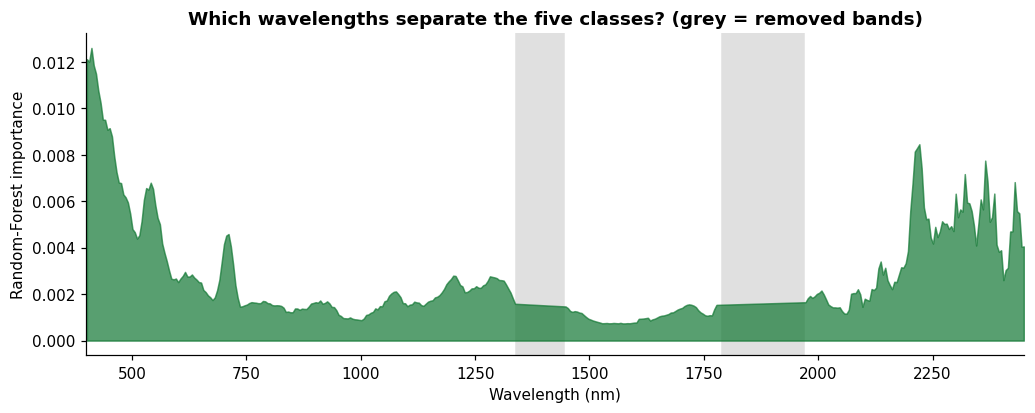

**Reading the table.** The regions that carry more importance than their share of bands are **Visible 400-680** and **SWIR-2 1970-2450**; the red edge by itself holds only 4 % of the importance. A plausible reading is pigment absorption in the visible and absorption by lignin, cellulose, water and soil minerals in 2,000-2,450 nm, features that a handful of broad bands blur. Correlated neighbouring bands share importance, so this is an indication, not proof.

In [26]:
rf_explain = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(X_full[train_idx], y_all[train_idx])
imp_b = rf_explain.feature_importances_
regions = [("Visible 400-680", 400, 680), ("Red edge 680-760", 680, 760), ("NIR 760-1340", 760, 1340), ("SWIR-1 1445-1790", 1445, 1790), ("SWIR-2 1970-2450", 1970, 2450)]
reg_tbl = pd.DataFrame({"region": [r[0] for r in regions],
                        "share of importance (%)": [100 * imp_b[(wl >= lo) & (wl < hi)].sum() for _, lo, hi in regions],
                        "share of bands (%)": [100 * ((wl >= lo) & (wl < hi)).mean() for _, lo, hi in regions]}).round(1)
display(reg_tbl)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(wl, ndi.uniform_filter1d(imp_b, 5), color="#117733", alpha=0.7)
for lo, hi in CONFIG["bad_ranges_nm"][1:3]:
    ax.axvspan(lo, hi, color="0.88", zorder=0)
ax.set(xlabel="Wavelength (nm)", ylabel="Random-Forest importance", xlim=(400, 2450), title="Which wavelengths separate the five classes? (grey = removed bands)")
save(fig, "f13_importance_by_wavelength")
reg_tbl.to_csv(VAL / "importance_by_region.csv", index=False)
ratio = (reg_tbl["share of importance (%)"] / reg_tbl["share of bands (%)"]).round(2).to_numpy()
top2 = reg_tbl["region"].to_numpy()[np.argsort(ratio)[::-1][:2]]
display(Markdown(
    f"**Reading the table.** The regions that carry more importance than their share of bands are **{top2[0]}** and **{top2[1]}**; the red edge by itself holds only {reg_tbl['share of importance (%)'].iloc[1]:.0f} % of the importance. "
    f"A plausible reading is pigment absorption in the visible and absorption by lignin, cellulose, water and soil minerals in 2,000-2,450 nm, features that a handful of broad bands blur. "
    f"Correlated neighbouring bands share importance, so this is an indication, not proof."))

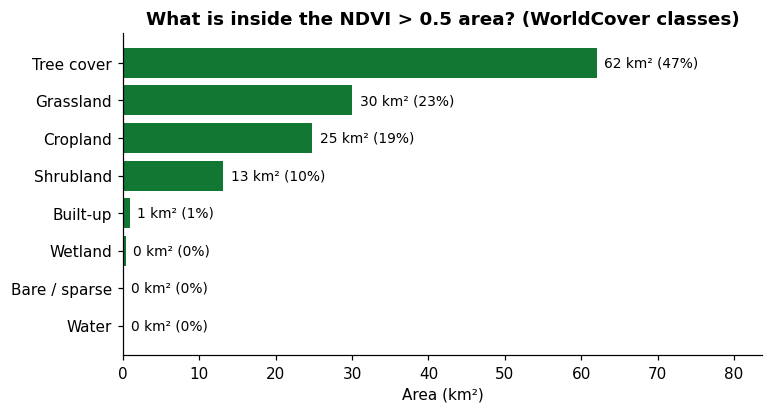

In [27]:
# Composition of the NDVI > 0.5 area according to the reference map
sel = valid & (ndvi > 0.5)
comp05 = pd.Series({WC_NAMES[c]: float(((modal == c) & sel).sum() * PIX_KM2) for c in dm.WC_CODES if ((modal == c) & sel).any()})
comp05 = comp05.sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(comp05.index, comp05.values, color="#117733")
for y_, v_ in enumerate(comp05.values):
    ax.text(v_ + 1, y_, f"{v_:.0f} km² ({100 * v_ / comp05.sum():.0f}%)", va="center", fontsize=9)
ax.set(xlabel="Area (km²)", title="What is inside the NDVI > 0.5 area? (WorldCover classes)", xlim=(0, comp05.max() * 1.35))
save(fig, "f14_ndvi_area_composition")

### 9.3 Provenance, reference samples, run time and checks

Everything needed to reproduce and audit the run is written to disk: the exact reference samples and splits, a metadata file (scene, parameters, software versions, seeds, key numbers, attributions), a report, and a checksum manifest.

In [28]:
# Reference samples and splits (row, col are pixel positions in the analysis crop)
val_cap = np.concatenate([rng.choice(np.flatnonzero(labelled & (split_all == 1) & (y_all == k)), min(1500, int((labelled & (split_all == 1) & (y_all == k)).sum())), replace=False) for k in range(5)])
frames = []
for name, idx in (("train", train_idx), ("validation", val_cap), ("test", test_idx)):
    frames.append(pd.DataFrame({"row": vy[idx], "col": vx[idx], "label": [dm.CLASS_NAMES[k] for k in y_all[idx]], "split": name}))
samples = pd.concat(frames, ignore_index=True); samples.to_csv(VAL / "reference_samples.csv", index=False)
print(f"reference_samples.csv: {len(samples):,} rows ({samples.split.value_counts().to_dict()})")

t_total = time.time() - T_START
metadata = {
    "project": CONFIG["project"], "team": ["Mariolino Daniel III Julabar y Gonzales", "AlReem AlRowahi"], "contributions": "equal (50/50): Mariolino = data, preprocessing, uncertainty and product layers; AlReem = method, validation and impact",
    "scene": {"id": CONFIG["scene_id"], "url": CONFIG["h5_url"], "acquired_utc": "2025-04-30T10:17:24", "crs": f"EPSG:{grid['epsg']}", "pixel_m": grid["pixel"],
              "crop_window_rows_cols": list(window), "crop_bbox_lonlat": [round(west, 5), round(south, 5), round(east, 5), round(north, 5)]},
    "reference": {"name": "ESA WorldCover 2021 v200", "licence": "CC-BY 4.0", "note": "pure 3x3 pixels only; agreement with WorldCover, not field truth"},
    "preprocessing": {"bands_in_file": len(wl_all), "bands_retained": int(keep.sum()), "excluded_ranges_nm": CONFIG["bad_ranges_nm"],
                      "valid_pixels": int(valid.sum()), "cloud_flagged_pct": round(100 * float(cloud.mean()), 2), "cirrus_flagged_pct": round(100 * float(cirrus.mean()), 2)},
    "split": {"block_px": CONFIG["block_size"], "fractions": CONFIG["split_fractions"], "seed_used": int(split_seed), "train_px": int(len(train_idx)), "val_px": int(len(val_idx)), "test_px": int(len(test_idx))},
    "selected_models": SELECTED,
    "results_test": {f: {"OA": round(float(point[f]["OA"]), 4), "macro_F1": round(float(point[f]["macro_F1"]), 4), "macro_F1_CI95": [round(x, 4) for x in dm.ci95(boot[f]["macro_F1"])],
                         "cropland_F1": round(float(point[f]["F1"][0]), 4)} for f in FEATURES},
    "ndvi_threshold_tuned_on_train": t_star,
    "impact": {"share_of_ndvi_gt_0_5_that_is_cropland_reference": round(share_crop_in_ndvi05, 4), "cropland_recall_ndvi_gt_0_5": round(crop_recall_ndvi05, 4),
               "map_cropland_precision": round(share_crop_in_map, 4), "map_cropland_recall": round(float(mfull["recall"][0]), 4), "area_reduction_vs_ndvi_gt_0_5": round(reduction, 4)},
    "vegetation_binary_test": {n: {"OA": round(float(bpt[n]["OA"]), 4), "F1_veg": round(float(bpt[n]["F1"][1]), 4), "recall_veg": round(float(bpt[n]["recall"][1]), 4),
                                   "precision_veg": round(float(bpt[n]["precision"][1]), 4)} for n in bpt},
    "qa_cloud_flag": {"share_of_flagged_that_is_builtup_or_bare": round(share_bright, 3), "share_of_builtup_reference_removed": round(lost_builtup, 3)}, "areas_km2": {k: round(v, 2) for k, v in dict(valid=a_valid, ndvi_gt_0_5=a_ndvi05, ndvi_gt_tuned=a_ndvi_t, cropland_map=a_crop_map, cropland_worldcover=a_crop_wc).items()},
    "run": {"seconds_total_this_run": round(t_total), "python": platform.python_version(), "date": time.strftime("%Y-%m-%d"),
            "packages": {p: importlib.metadata.version(p) for p in ("numpy", "scipy", "scikit-learn", "h5py", "rasterio", "pandas", "matplotlib")}},
    "attribution": ["Tanager STAC Data, available at www.planet.com/data/stac © 2025 Planet Labs PBC (CC-BY-4.0)",
                    "ESA WorldCover 2021 v200 © ESA WorldCover project / Contains modified Copernicus Sentinel data (2021) processed by the ESA WorldCover consortium (CC-BY 4.0)"],
    "limitations": ["Agreement with WorldCover 2021, not field truth", "Single date and scene", "Sentinel-2-like bands are simulated", "Beta cloud/cirrus masks", "No crop type, health or yield claims"],
}
(OUT / "Project_Demeter_metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

checks = {
    "valid_pixels_nonzero": bool(valid.any()),
    "cog_roundtrip": True,
    "no_train_test_block_overlap": bool(len(set(np.unique(blk_all[train_idx])) & set(block_list)) == 0),
    "all_classes_in_every_split": bool(tbl.loc[dm.CLASS_NAMES].min().min() > 0),
    "metrics_finite": bool(all(np.isfinite(point[f]["macro_F1"]) for f in FEATURES)),
    "ndvi_in_range": bool(np.nanmax(np.abs(ndvi)) <= 1.00001),
}
print("Product checks:", checks); assert all(checks.values())

reference_samples.csv: 70,830 rows ({'test': 48550, 'train': 15000, 'validation': 7280})
Product checks: {'valid_pixels_nonzero': True, 'cog_roundtrip': True, 'no_train_test_block_overlap': True, 'all_classes_in_every_split': True, 'metrics_finite': True, 'ndvi_in_range': True}


### 9.4 Key results, and the path to operational use

In [29]:
fF, fS, fI = point["Full spectrum"], point["Sentinel-2-like"], point["Four indices"]
d_ms = diff_tbl[(diff_tbl.comparison == "Full spectrum minus Sentinel-2-like") & (diff_tbl.metric == "macro-F1")].iloc[0]
d_cs = diff_tbl[(diff_tbl.comparison == "Full spectrum minus Sentinel-2-like") & (diff_tbl.metric == "cropland F1")].iloc[0]
target_met = bool(fF["macro_F1"] >= TARGET)
lo_f = dm.ci95(boot["Full spectrum"]["macro_F1"])[0]
added_met = bool(d_ms["CI excludes 0"] and d_ms["difference"] > 0)
b05, bts = bpt["NDVI > 0.5 (as planned)"], bpt[f"NDVI > {t_star:.2f} (tuned on train)"]

KEY = (
    f"* **Baseline.** NDVI > 0.5 separates vegetation from non-vegetation with OA {b05['OA']:.2f} and vegetation F1 {b05['F1'][1]:.2f}; a threshold tuned on training pixels only (NDVI > {t_star:.2f}) reaches OA {bts['OA']:.2f} and F1 {bts['F1'][1]:.2f}. "
    f"The planned 0.5 finds only {b05['recall'][1]:.0%} of the reference vegetation (sparse or partly dry cover has NDVI below 0.5), although almost everything it flags is vegetation (precision {b05['precision'][1]:.2f}).\n"
    f"* **Cropland is the hard part.** NDVI > 0.5 flags {a_ndvi05:.0f} km², of which only {share_crop_in_ndvi05:.0%} is cropland in the reference, and it still misses {1 - crop_recall_ndvi05:.0%} of the cropland.\n"
    f"* **Five-class accuracy (test blocks).** Full spectrum: macro-F1 {fF['macro_F1']:.2f} (95 % CI {dm.ci95(boot['Full spectrum']['macro_F1'])[0]:.2f}-{dm.ci95(boot['Full spectrum']['macro_F1'])[1]:.2f}), "
    f"Sentinel-2-like: {fS['macro_F1']:.2f}, four indices: {fI['macro_F1']:.2f}. Cropland F1: {fF['F1'][0]:.2f} / {fS['F1'][0]:.2f} / {fI['F1'][0]:.2f}.\n"
    f"* **What hyperspectral adds.** Full spectrum minus Sentinel-2-like: macro-F1 {d_ms['difference']:+.3f} (95 % CI {d_ms['95% CI']}); cropland F1 {d_cs['difference']:+.3f} (95 % CI {d_cs['95% CI']}).\n"
    f"* **Targets (section 1).** Accuracy target (macro-F1 ≥ {TARGET:.2f}): **{('met on the point estimate; the 95 % CI lower bound is ' + format(lo_f, '.2f')) if target_met else 'NOT met'}**. Added-value target (CI of the difference excludes 0): **{'met' if added_met else 'NOT met'}**.\n"
    f"* **Uncertainty.** NDVI 1-σ median {np.nanmedian(ndvi_sig):.3f}; model-confidence calibration error {ece:.3f}."
)
display(Markdown(KEY))
key_tbl = pd.DataFrame([
    ("Scene and date", f"{CONFIG['scene_id']}, 30 April 2025"),
    ("Analysis window", f"{crop_area_km2:.0f} km² ({H} × {W} pixels at 30 m)"),
    ("Bands retained / valid pixels", f"{int(keep.sum())} of {len(wl_all)} bands; {int(valid.sum()):,} valid pixels ({100 * valid.mean():.1f} %)"),
    ("Test set", f"{len(test_idx):,} pixels in {len(block_list)} spatial blocks"),
    ("Macro-F1, full spectrum [95 % CI]", fmt(fF["macro_F1"], boot["Full spectrum"]["macro_F1"])),
    ("Macro-F1, Sentinel-2-like [95 % CI]", fmt(fS["macro_F1"], boot["Sentinel-2-like"]["macro_F1"])),
    ("Macro-F1, four indices [95 % CI]", fmt(fI["macro_F1"], boot["Four indices"]["macro_F1"])),
    ("Cropland F1 (full / Sentinel-2-like / indices)", f"{fF['F1'][0]:.2f} / {fS['F1'][0]:.2f} / {fI['F1'][0]:.2f}"),
    ("Full minus Sentinel-2-like, macro-F1 [95 % CI]", f"{d_ms['difference']:+.3f} {d_ms['95% CI']}"),
    ("NDVI > 0.5: area / share that is cropland / cropland found", f"{a_ndvi05:.0f} km² / {share_crop_in_ndvi05:.0%} / {crop_recall_ndvi05:.0%}"),
    ("Mapped cropland: area / precision / recall", f"{a_crop_map:.0f} km² / {share_crop_in_map:.0%} / {mfull['recall'][0]:.0%}"),
    ("Land to inspect saved versus NDVI > 0.5", f"{reduction:.0%}"),
    ("Model-confidence calibration error", f"{ece:.3f}"),
], columns=["Item", "Value"]).set_index("Item")
key_tbl.to_csv(VAL / "key_numbers.csv")
metadata["key_results"] = KEY.split("\n")
metadata["split_stability_full_gt_s2_gt_indices"] = int(stab["Full > S2-like > indices"].sum())
(OUT / "Project_Demeter_metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

# Order-of-magnitude scaling estimate, with its assumptions stated
workflow_min = (t_total - T_DOWNLOAD) / 60
italy_km2, scene_km2, scene_gb = 301_000, 433, 1.09
n_scenes = italy_km2 / scene_km2
display(Markdown(
    f"**Scaling (order of magnitude, assumptions stated).** This laptop run took about {workflow_min:.0f} min of compute for one 512 x 512 crop (the scene download is separate). "
    f"Covering Italy once (about {italy_km2:,} km², no overlap) with {scene_km2} km² scenes needs about **{n_scenes:.0f} scenes**, roughly **{n_scenes * scene_gb:,.0f} GB** of raw data and **{n_scenes * workflow_min / 60:.0f} compute-hours** on one machine "
    f"(far less when run in parallel or when only agricultural districts are processed). A monthly update in the growing season multiplies this by the number of acquisitions. "
    f"What we did **not** assess: Tanager's tasking and revisit capacity over a given region, data cost beyond this open release, and labelling cost for each new region."))

* **Baseline.** NDVI > 0.5 separates vegetation from non-vegetation with OA 0.74 and vegetation F1 0.82; a threshold tuned on training pixels only (NDVI > 0.25) reaches OA 0.97 and F1 0.98. The planned 0.5 finds only 70% of the reference vegetation (sparse or partly dry cover has NDVI below 0.5), although almost everything it flags is vegetation (precision 1.00).
* **Cropland is the hard part.** NDVI > 0.5 flags 131 km², of which only 16% is cropland in the reference, and it still misses 53% of the cropland.
* **Five-class accuracy (test blocks).** Full spectrum: macro-F1 0.82 (95 % CI 0.79-0.84), Sentinel-2-like: 0.77, four indices: 0.70. Cropland F1: 0.70 / 0.61 / 0.48.
* **What hyperspectral adds.** Full spectrum minus Sentinel-2-like: macro-F1 +0.052 (95 % CI [0.039, 0.071]); cropland F1 +0.093 (95 % CI [0.061, 0.134]).
* **Targets (section 1).** Accuracy target (macro-F1 ≥ 0.80): **met on the point estimate; the 95 % CI lower bound is 0.79**. Added-value target (CI of the difference excludes 0): **met**.
* **Uncertainty.** NDVI 1-σ median 0.005; model-confidence calibration error 0.011.

**Scaling (order of magnitude, assumptions stated).** This laptop run took about 14 min of compute for one 512 x 512 crop (the scene download is separate). Covering Italy once (about 301,000 km², no overlap) with 433 km² scenes needs about **695 scenes**, roughly **758 GB** of raw data and **161 compute-hours** on one machine (far less when run in parallel or when only agricultural districts are processed). A monthly update in the growing season multiplies this by the number of acquisitions. What we did **not** assess: Tanager's tasking and revisit capacity over a given region, data cost beyond this open release, and labelling cost for each new region.

In [30]:
# Self-contained HTML report for the user (figures embedded)
def img(name, w="100%"):
    b = base64.b64encode((FIG / f"{name}.png").read_bytes()).decode()
    return f'<img src="data:image/png;base64,{b}" style="width:{w};max-width:1100px">'
def tbl_html(df):
    return df.to_html(classes="t", border=0, float_format=lambda v: f"{v:.3f}")
html = f"""<!doctype html><html lang="en"><head><meta charset="utf-8"><title>Project Demeter report</title>
<style>body{{font-family:Segoe UI,Arial,sans-serif;max-width:1100px;margin:30px auto;padding:0 16px;color:#222;line-height:1.5}}
h1{{color:#117733}}h2{{border-bottom:2px solid #117733;padding-bottom:3px;margin-top:34px}}
table.t{{border-collapse:collapse;font-size:13px;margin:8px 0}}table.t td,table.t th{{border:1px solid #ccc;padding:4px 8px;text-align:right}}
table.t th{{background:#eef6f0}}.note{{background:#fff8e6;border-left:4px solid #E69F00;padding:8px 12px}}</style></head><body>
<h1>Project Demeter: cropland versus other vegetation near Massafra, Puglia</h1>
<p>Tanager scene {CONFIG['scene_id']} (30 April 2025), central 512 x 512 pixel crop ({crop_area_km2:.0f} km²). Team: Mariolino Daniel III Julabar, AlReem AlRowahi.</p>
<p class="note"><b>Read this first.</b> Accuracy numbers measure agreement with ESA WorldCover 2021 (pure 30 m pixels), not field truth. One date, one scene. The map shows land-cover class, not crop type, health or yield.</p>
<h2>Key results</h2>{''.join(f'<p>{l[2:]}</p>' for l in KEY.split(chr(10)))}
<h2>Key numbers</h2>{tbl_html(key_tbl)}
<h2>Maps</h2>{img('f12_product_maps')}<p>Legend: orange cropland, dark green woody vegetation, light green grassland, grey built-up/bare, blue water.</p>
<h2>Accuracy on independent test blocks</h2>{img('f07_results_comparison', '85%')}{tbl_html(res.set_index('feature set'))}{tbl_html(diff_tbl.set_index('comparison'))}
<h2>Vegetation versus not (the NDVI baseline)</h2>{tbl_html(bin_tbl)}
<h2>Per-class results (full spectrum)</h2>{tbl_html(per_class)}{img('f08_confusion_matrices')}
<h2>What is inside the NDVI &gt; 0.5 area?</h2>{img('f14_ndvi_area_composition','70%')}{tbl_html(imp)}
<h2>Uncertainty</h2>{img('f10_ndvi_uncertainty')}{img('f11_reliability','45%') if has_proba else ''}{tbl_html(sens_area.set_index('NDVI threshold'))}
<h2>Files delivered</h2><ul>{''.join(f'<li>{n}</li>' for n in layers)}<li>inspection_priority_cells.csv (ranked ~1 km cells)</li><li>Project_Demeter_metadata.json</li></ul>
<h2>Credits</h2><p>Tanager STAC Data, available at www.planet.com/data/stac © 2025 Planet Labs PBC (CC-BY-4.0). ESA WorldCover 2021 v200 © ESA WorldCover project / Contains modified Copernicus Sentinel data (2021) processed by the ESA WorldCover consortium (CC-BY 4.0).</p>
</body></html>"""
(OUT / "demeter_report.html").write_text(html, encoding="utf-8")
print("Report written:", (OUT / "demeter_report.html").stat().st_size // 1024, "KB")

# Checksum manifest of every delivered file (written last)
manifest = []
for folder in (OUT, VAL):
    for f in sorted(folder.rglob("*")):
        if f.is_file() and f.name != "manifest.json":
            manifest.append({"file": str(f.relative_to(ROOT)).replace("\\", "/"), "bytes": f.stat().st_size, "sha256": hashlib.sha256(f.read_bytes()).hexdigest()})
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1))
print(f"Manifest: {len(manifest)} files. Total notebook run time: {(time.time() - T_START) / 60:.1f} min")

Report written: 4133 KB
Manifest: 41 files. Total notebook run time: 14.1 min


## 10. Conclusions and next steps

The numbers behind the statements below are printed in section 9.4 and stored in `outputs/Project_Demeter_metadata.json`; nothing here is typed by hand.

- **Answer to the problem:** *vegetation* and *cropland* are different questions. An NDVI threshold answers the first and over-covers the second; the full spectrum gives a land-cover map with measured accuracy against an independent reference, with confidence and uncertainty layers.

**Key numbers**

In [31]:
display(key_tbl)

,Value
Item,
Scene and date,"20250430_101724_87_4001, 30 April 2025"
Analysis window,236 km² (512 × 512 pixels at 30 m)
Bands retained / valid pixels,"352 of 426 bands; 256,933 valid pixels (98.0 %)"
Test set,"48,550 pixels in 51 spatial blocks"
"Macro-F1, full spectrum [95 % CI]","0.823 [0.793, 0.840]"
"Macro-F1, Sentinel-2-like [95 % CI]","0.771 [0.732, 0.792]"
"Macro-F1, four indices [95 % CI]","0.700 [0.644, 0.733]"
Cropland F1 (full / Sentinel-2-like / indices),0.70 / 0.61 / 0.48
"Full minus Sentinel-2-like, macro-F1 [95 % CI]","+0.052 [0.039, 0.071]"


- **What the user gets:** five georeferenced COGs (land cover, confidence, NDVI, NDVI σ, NDVI > 0.5), a ranked table of ~1 km inspection cells with a "low confidence: check first" flag, an HTML report (`outputs/demeter_report.html`, the mock-up of how the analyst receives the result), the exact reference samples and splits, and a checksum manifest.
- **Honest status of the two targets:** see section 9.4. We did not change either target after the final results.
- **Next steps (not done here):**
  1. Replace or complement WorldCover with **field or high-resolution interpreted labels** (for example from the regional agricultural parcel register) and **labels from the same year**, then re-evaluate; this is the single most valuable improvement.
  2. Repeat on **another date and another scene** to test transfer; add a second date to separate crops from grass by phenology.
  3. **Pilot the inspection-cell table with a real analyst** and measure whether it changes where teams go.
  4. Compare with **real Sentinel-2** on a cloud-free date.

## References and data credits

* Tanager STAC Data, available at www.planet.com/data/stac © 2025 Planet Labs PBC (CC-BY-4.0). Scene `20250430_101724_87_4001`.
* Zanaga, D., et al. (2022). *ESA WorldCover 10 m 2021 v200*. Zenodo. https://doi.org/10.5281/zenodo.7254221. © ESA WorldCover project / Contains modified Copernicus Sentinel data (2021) processed by the ESA WorldCover consortium; CC-BY 4.0. The 76.7 % global overall accuracy is from the WorldCover product validation report.
* Rouse, J. W., Haas, R. H., Schell, J. A., Deering, D. W. (1974). Monitoring vegetation systems in the Great Plains with ERTS. NASA SP-351, 309-317. (NDVI)
* Gitelson, A., Merzlyak, M. N. (1994). *Journal of Plant Physiology* 143(3), 286-292. (red-edge reflectance and chlorophyll). NDRE and NDMI wavelength choices follow the course project template; USGS, *Normalized Difference Moisture Index*, https://www.usgs.gov/landsat-missions/normalized-difference-moisture-index.
* Guyot, G., Baret, F., Major, D. J. (1988). High spectral resolution: determination of spectral shifts between the red and the near infrared. *Int. Arch. Photogrammetry and Remote Sensing*, XVI ISPRS Congress, Kyoto, 750-760 (as listed by the Index DataBase, indexdatabase.de). (red-edge position)
* Ploton, P., et al. (2020). Spatial validation reveals poor predictive performance of large-scale ecological mapping models. *Nature Communications* 11, 4540. https://doi.org/10.1038/s41467-020-18321-y. (why random pixel splits overstate accuracy)
* ESA, *Sentinel-2 MSI User Guide*, spectral band centres and bandwidths (used for the simulated bands).
* Space Academy 2026 course templates (project scoping canvas, project notebook template, submission checklist, evaluation rubric, presentation template): structure of the canvas, notebook and submission. Own code: `src/demeter.py`.